# San Rafael LV Grid Impact Study v5
## pandapower model with stochastic household demand and NASA POWER solar data

This notebook evaluates the local distribution network around EPM transformer 94022.

The annual load input is the reproducible stochastic household demand set used by PyPSA v18. Solar output for the grid study is calculated independently from NASA POWER hourly irradiance and is kept at its native pvlib-derived annual yield rather than being normalized to the HOMER result.

The study checks transformer loading, MV/LV conductor loading, voltage drop, voltage rise, reverse power flow, 4 to 8-house sensitivities and transformer headroom.

The shared 5 kW inverter is connected at the transformer LV bus.

## v5 robustness extension

This revision keeps the existing four-house reference model and adds:

- optional use of percentile-based Monte Carlo demand snapshots from PyPSA v18
- an explicit split between fixed-existing-route headroom and route-expansion sensitivity
- a one-shot analytical validation of the balanced equivalent
- inverter reactive-power sensitivity at maximum export
- all main assumptions and run controls are visible in the notebook configuration cell

The network model remains supplementary to the annual PyPSA energy study.


## 1. Single-phase equivalent

Transformer 94022 is a 7.621 kV / 240-120 V single-phase transformer. The standard pandapower solver uses a balanced three-phase representation, so the physical network is represented with an equivalent three-phase model.

The mapping is:

- equivalent voltage = `sqrt(3) × physical single-phase voltage`
- equivalent power = `3 × physical single-phase power`
- equivalent transformer rating = `3 × physical transformer rating`

With this mapping, per-unit voltage, conductor current and transformer loading percentage remain consistent with the physical single-phase system. Reported active power is converted back to the physical single-phase value.

For the 240 V secondary circuit, the LV line uses twice the single-conductor series impedance to represent the two-conductor current path.

## 2. Network data and assumptions

Input values are taken in the following order:

1. EPM asset data supplied for the site
2. EPM technical standards
3. manufacturer data for the identified conductor type
4. engineering assumptions where no site-specific value is available

### Site data

- transformer: 94022
- node: 931076
- circuit: 221-12
- primary voltage: 7.621 kV
- secondary voltage: 240/120 V
- transformer rating: 5 kVA
- primary conductor: #2 ACSR
- secondary conductor: 1/0 AAC
- primary route: approximately 354.2 m
- secondary route: approximately 324.5 m

### EPM references

**ET-TD-ME01-03, Cables ACSR**
- #2 AWG ACSR Sparrow
- DC resistance at 20 °C: 0.8320 Ω/km

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/ET-TD-ME01-03.pdf

**ET-TD-ME01-02, Cables AAC aislados**
- 1/0 AWG AAC
- DC resistance at 20 °C: 0.538 Ω/km

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/ET-TD-ME01-02.pdf

**ET-TD-ME01-06, Cable multiplex**
- includes 1/0 AAC phase conductors for secondary multiplex arrangements

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/ET-TD-ME01-06.pdf

**RA4-100**
- 5 kVA, 7620 V / 240-120 V single-phase transformer: 20.8 A nominal LV current

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/RA4_100.pdf

**RA8-017**
- residential calculations use power factor 0.9
- 3% voltage-drop reference from transformer secondary to metering point
- 0.656 Ω/km AC resistance reference for 1/0 aluminium conductor

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/RA8-017.pdf

### Manufacturer reference

Nexans Colombia lists an ampacity of about 184 A for #2 ACSR Sparrow.

https://www.nexans.co/en/products/Sistemas-Solares/Granjas-Solares/Cables-solar-premium-ACSR/ACSR.html

### Values not available from the site data

The exact impedance and loss data for transformer 94022 are not available. Transformer `vk`, `vkr`, no-load loss and magnetising current are therefore kept as explicit assumptions at the top of the notebook.

The installation-specific reactance and ampacity of the local 1/0 AAC secondary are also not known. Line-loading results should therefore be treated as screening values.

## 3. Installation and input files

Install the required packages with:

```bash
pip install -r SanRafael_pandapower_requirements.txt
```

Required inputs:

- `stochastic_household_load_profiles.csv`, generated by the PyPSA v18 notebook
- `NASA_POWER_SanRafael_hourly_2025.csv`

The stochastic file contains individual household profiles and aggregate profiles for groups up to 20 houses. If available, PyPSA v18 supplies separate percentile planning snapshots: `monte_carlo_p95_load_snapshots.csv` for import stress and `monte_carlo_p95_export_snapshot.csv` for reverse-flow stress. The annual time-series run itself remains the fixed-seed chronological reference realization.

Results are written to `pandapower_results_nasa/`.

In [1]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pvlib

try:
    from IPython.display import display, Image
except ImportError:
    display = print
    Image = None

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
RESULTS_DIR = ROOT / "pandapower_results_nasa"
FIGURES_DIR = RESULTS_DIR / "figures"

RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

print("pandapower version:", pp.__version__)
print("pvlib version:", pvlib.__version__)
print("Working directory:", ROOT.resolve())


pandapower version: 3.4.0
pvlib version: 0.15.0
Working directory: D:\0. UoL\SEEDExchange\sanrafaelutility-main


In [2]:
# ============================================================
# 4. GLOBAL CONFIGURATION - EDIT ASSUMPTIONS HERE
# ============================================================

# ------------------------------------------------------------
# Grouping and stochastic demand
# ------------------------------------------------------------

HOUSE_COUNTS = [4, 5, 6, 7, 8]
REFERENCE_HOUSES = 4
HOUSES_PER_TAP = 2

# Must match the PyPSA stochastic-load export being used.
STOCHASTIC_LOAD_SEED = 20250913
STOCHASTIC_PROFILE_HOUSE_COUNT = 20

# ------------------------------------------------------------
# Electrical source / transformer
# ------------------------------------------------------------

TRF_NUMBER = 94022
TRF_NODE = 931076
CIRCUIT = "221-12"

MV_PHYSICAL_KV = 7.621
LV_PHYSICAL_KV = 0.240
TRF_PHYSICAL_KVA = 5.0

# Single-phase -> balanced pandapower equivalent
PP_POWER_SCALE = 3.0
MV_EQ_KV = math.sqrt(3) * MV_PHYSICAL_KV
LV_EQ_KV = math.sqrt(3) * LV_PHYSICAL_KV
TRF_EQ_MVA = PP_POWER_SCALE * TRF_PHYSICAL_KVA / 1000.0

# Image-derived route lengths
MV_ROUTE_M = 354.2
LV_ROUTE_M = 324.5

# Residential power factor.
# EPM RA8-017 uses fp = 0.9 in its residential conductor calculations.
LOAD_POWER_FACTOR = 0.90

# ------------------------------------------------------------
# NASA / PV configuration
# ------------------------------------------------------------

SITE_LAT = 6.2523
SITE_LON = -75.0143
SITE_ALTITUDE_M = 1291.33

PV_ARRAY_KWP = 5.22
PV_SURFACE_TILT_DEG = 5.0

# pvlib convention: 180 degrees = south.
# This is used as the equator-facing interpretation of the
# HOMER 0-degree azimuth setting. At 5-degree tilt the azimuth
# sensitivity is small.
PV_SURFACE_AZIMUTH_DEG = 180.0

PV_DERATING_FACTOR = 0.80
PV_TEMP_COEFF_PER_C = -0.003
PV_NOCT_C = 45.0

INVERTER_AC_LIMIT_KW = 5.0
INVERTER_EFFICIENCY = 0.95

HOMER_REFERENCE_PV_DC_KWH = 7326.3

# NASA file was downloaded with time-standard=LST.
# The site longitude is almost exactly the UTC-5 standard meridian,
# so the hourly labels are aligned directly to the project's 2025
# load-clock timestamps for this grid-screening study.
NASA_TIMEZONE_FOR_SOLAR_POSITION = "Etc/GMT+5"

# NASA POWER hourly irradiance values are treated as hour-average
# values labelled at the beginning of the interval. Solar position is
# therefore evaluated at the +30 minute interval midpoint.
SOLAR_POSITION_INTERVAL_MIDPOINT_MIN = 30

# GHI is retained as the irradiance anchor. DNI and DHI used for PV
# transposition are derived from GHI with the Erbs decomposition.
IRRADIANCE_DECOMPOSITION_METHOD = "ERBS_FROM_GHI"

# Diagnostics for a nearly horizontal 5 degree array.
POA_TO_GHI_ANNUAL_RATIO_MIN = 0.98
POA_TO_GHI_ANNUAL_RATIO_MAX = 1.05
COMPONENT_CLOSURE_MAX_REL_ERROR = 0.02

# ------------------------------------------------------------
# EPM / literature-based conductor values
# ------------------------------------------------------------

# #2 ACSR Sparrow, EPM ET-TD-ME01-03
MV_R_OHM_PER_KM = 0.8320

# Reactance is installation / geometry dependent.
MV_X_OHM_PER_KM = 0.40

# Supplementary manufacturer reference for #2 ACSR Sparrow.
MV_MAX_I_KA = 0.184

# 1/0 AAC:
# EPM ET-TD-ME01-02 gives 0.538 ohm/km DC at 20 C.
# EPM RA8-017 gives 0.656 ohm/km AC as a 1/0 Al reference.
LV_R_SINGLE_OHM_PER_KM = 0.656

# Installation-specific reactance is not available.
LV_X_SINGLE_OHM_PER_KM = 0.08

# 240 V current flows through a two-conductor loop.
LV_R_LOOP_OHM_PER_KM = 2 * LV_R_SINGLE_OHM_PER_KM
LV_X_LOOP_OHM_PER_KM = 2 * LV_X_SINGLE_OHM_PER_KM

# Screening ampacity pending exact installation-specific value.
LV_MAX_I_KA = 0.150

# ------------------------------------------------------------
# Transformer parameters
# ------------------------------------------------------------
# Exact nameplate data for transformer 94022 are not available.
# These remain engineering proxies.

TRF_VK_PERCENT = 3.0
TRF_VKR_PERCENT = 1.8
TRF_PFE_PHYSICAL_KW = 0.030
TRF_I0_PERCENT = 2.5

# ------------------------------------------------------------
# Voltage / loading screening references
# ------------------------------------------------------------

LV_SCREEN_MIN_PU = 0.97
LV_SCREEN_MAX_PU = 1.03

TRF_NOMINAL_LIMIT_PERCENT = 100.0
LINE_LIMIT_PERCENT = 100.0

# ------------------------------------------------------------
# Deterministic DER stress cases
# ------------------------------------------------------------

CLEAR_SKY_INVERTER_KW = [4.0, 4.5, 5.0]

# Optional transformer headroom study.
HEADROOM_HOUSE_COUNTS = list(range(1, 21))

# ------------------------------------------------------------
# v5 robustness configuration
# ------------------------------------------------------------

# Existing-route headroom is always available.
RUN_FIXED_ROUTE_HEADROOM = True

# Expansion sensitivity remains disabled until a measured or explicitly
# chosen added-tap spacing is available. Set a value in metres to enable it.
EXPANSION_SEGMENT_M = None
RUN_EXPANSION_SENSITIVITY = EXPANSION_SEGMENT_M is not None

RUN_MC_P95_SNAPSHOTS = True
RUN_MC_P95_EXPORT_SNAPSHOT = True
RUN_EQUIVALENT_VALIDATION = True
RUN_INVERTER_Q_SENSITIVITY = True

Q_SENSITIVITY_POWER_FACTORS = [1.0, 0.98, 0.95]

print(
    "Route-expansion sensitivity:",
    (
        f"enabled, +{EXPANSION_SEGMENT_M:.1f} m per added tap"
        if RUN_EXPANSION_SENSITIVITY
        else "disabled until EXPANSION_SEGMENT_M is supplied in this cell"
    ),
)


Route-expansion sensitivity: disabled until EXPANSION_SEGMENT_M is supplied in this cell


In [3]:
# ============================================================
# 5. ROBUST INPUT LOCATOR
# ============================================================

SEARCH_DIRS = [
    ROOT,
    ROOT / "results",
    ROOT / "data",
    ROOT / "NASA Data",
    ROOT.parent,
]

def find_input(candidates, required=True):
    for directory in SEARCH_DIRS:
        for name in candidates:
            p = directory / name
            if p.exists():
                return p

    for directory in SEARCH_DIRS:
        if not directory.exists():
            continue
        for name in candidates:
            hits = list(directory.rglob(name))
            if hits:
                return hits[0]

    if required:
        raise FileNotFoundError(
            "Could not find any of:\n- " + "\n- ".join(candidates)
        )
    return None


STOCHASTIC_LOAD_PATH = find_input([
    "stochastic_household_load_profiles.csv",
])


MC_P95_SNAPSHOT_PATH = find_input([
    "monte_carlo_p95_load_snapshots.csv",
], required=False)

MC_P95_EXPORT_PATH = find_input([
    "monte_carlo_p95_export_snapshot.csv",
], required=False)

HANDOFF_PATH = find_input([
    "pandapower_handoff_S2_REFERENCE_PV_BESS.csv",
    "pandapower_handoff_S2_REFERENCE_PV_BESS(3).csv",
    "pandapower_handoff_S2_REFERENCE_PV_BESS(2).csv",
    "pandapower_handoff_S2_REFERENCE_PV_BESS(1).csv",
], required=False)

NASA_PATH = find_input([
    "NASA_POWER_SanRafael_hourly_2025.csv",
])

METADATA_PATH = find_input([
    "pandapower_metadata_S2_REFERENCE_PV_BESS.csv",
    "pandapower_metadata_S2_REFERENCE_PV_BESS(3).csv",
    "pandapower_metadata_S2_REFERENCE_PV_BESS(2).csv",
    "pandapower_metadata_S2_REFERENCE_PV_BESS(1).csv",
], required=False)

CORE_CASES_PATH = find_input([
    "core_cases.csv",
    "core_cases(7).csv",
    "core_cases(6).csv",
    "core_cases(5).csv",
], required=False)

ASSET_PATH = find_input([
    "san_rafael_epm_asset_94022.csv",
], required=False)

GEOMETRY_PATH = find_input([
    "san_rafael_epm_local_geometry_v2.csv",
], required=False)

print("Stochastic household load file:", STOCHASTIC_LOAD_PATH)
print("Optional PyPSA handoff:", HANDOFF_PATH)
print("NASA POWER hourly file:", NASA_PATH)
print("PyPSA metadata:", METADATA_PATH)
print("Core cases:", CORE_CASES_PATH)
print("Asset file:", ASSET_PATH)
print("Geometry file:", GEOMETRY_PATH)
print("Optional Monte Carlo P95 demand snapshots:", MC_P95_SNAPSHOT_PATH)
print("Optional Monte Carlo P95 export snapshot:", MC_P95_EXPORT_PATH)


Stochastic household load file: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\stochastic_household_load_profiles.csv
Optional PyPSA handoff: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_handoff_S2_REFERENCE_PV_BESS.csv
NASA POWER hourly file: d:\0. UoL\SEEDExchange\sanrafaelutility-main\NASA_POWER_SanRafael_hourly_2025.csv
PyPSA metadata: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_metadata_S2_REFERENCE_PV_BESS.csv
Core cases: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\core_cases.csv
Asset file: d:\0. UoL\SEEDExchange\sanrafaelutility-main\SanRafael_Reproducible_Model_Package_v1\SanRafael_Reproducible_Model_Package\04_grid_data\san_rafael_epm_asset_94022.csv
Geometry file: d:\0. UoL\SEEDExchange\sanrafaelutility-main\SanRafael_Reproducible_Model_Package_v1\SanRafael_Reproducible_Model_Package\04_grid_data\san_rafael_epm_local_geometry_v2.csv
Optional Monte Carlo P95 demand snapshots: d:\0. UoL\SEEDExchange\sanrafaelutility-main\re

In [4]:
# ============================================================
# 6. LOAD SOURCE DATA
# ============================================================

stochastic_loads = pd.read_csv(
    STOCHASTIC_LOAD_PATH,
    parse_dates=["timestamp"],
)

nasa = pd.read_csv(
    NASA_PATH,
    parse_dates=["timestamp_lst"],
)

mc_p95_snapshots = (
    pd.read_csv(
        MC_P95_SNAPSHOT_PATH,
        parse_dates=["selected_timestamp"],
    )
    if MC_P95_SNAPSHOT_PATH is not None
    else pd.DataFrame()
)

mc_p95_export_snapshot = (
    pd.read_csv(
        MC_P95_EXPORT_PATH,
        parse_dates=["selected_timestamp"],
    )
    if MC_P95_EXPORT_PATH is not None
    else pd.DataFrame()
)

handoff = (
    pd.read_csv(HANDOFF_PATH, parse_dates=["timestamp"])
    if HANDOFF_PATH is not None
    else pd.DataFrame()
)

metadata = (
    pd.read_csv(METADATA_PATH)
    if METADATA_PATH is not None
    else pd.DataFrame()
)

core_cases = (
    pd.read_csv(CORE_CASES_PATH)
    if CORE_CASES_PATH is not None
    else pd.DataFrame()
)

asset = (
    pd.read_csv(ASSET_PATH)
    if ASSET_PATH is not None
    else pd.DataFrame()
)

geometry = (
    pd.read_csv(GEOMETRY_PATH)
    if GEOMETRY_PATH is not None
    else pd.DataFrame()
)

required_house_columns = {
    f"house_{h}_kw"
    for h in range(1, STOCHASTIC_PROFILE_HOUSE_COUNT + 1)
}

required_group_columns = {
    f"load_{h}hh_kw"
    for h in range(1, STOCHASTIC_PROFILE_HOUSE_COUNT + 1)
}

missing = (
    {"timestamp"}
    | required_house_columns
    | required_group_columns
) - set(stochastic_loads.columns)

if missing:
    raise ValueError(
        "Stochastic load file is missing required columns:\n"
        + "\n".join(sorted(missing))
    )

required_nasa_columns = {
    "timestamp_lst",
    "ALLSKY_SFC_SW_DWN",
    "ALLSKY_SFC_SW_DIFF",
    "ALLSKY_SFC_SW_DNI",
    "CLRSKY_SFC_SW_DWN",
    "T2M",
    "WS10M",
}

missing = required_nasa_columns - set(nasa.columns)

if missing:
    raise ValueError(
        f"NASA hourly file is missing required columns: {sorted(missing)}"
    )

for col in sorted(required_nasa_columns - {"timestamp_lst"}):
    nasa[col] = pd.to_numeric(nasa[col], errors="coerce")
    nasa.loc[nasa[col] <= -900, col] = np.nan

if nasa[list(required_nasa_columns - {"timestamp_lst"})].isna().any().any():
    raise ValueError("NASA hourly file contains missing/fill values")

load_summary = pd.DataFrame([
    {
        "houses": houses,
        "annual_load_kwh":
            stochastic_loads[f"load_{houses}hh_kw"].sum(),
        "peak_load_kw":
            stochastic_loads[f"load_{houses}hh_kw"].max(),
        "average_load_kw":
            stochastic_loads[f"load_{houses}hh_kw"].mean(),
    }
    for houses in HOUSE_COUNTS
])

display(load_summary.round(4))

,houses,annual_load_kwh,peak_load_kw,average_load_kw
0,4,7592.0,2.1667,0.8667
1,5,9490.0,2.5193,1.0833
2,6,11388.0,2.9979,1.3000
3,7,13286.0,3.7174,1.5167
4,8,15184.0,4.1833,1.7333


## 7. PV profile from NASA POWER

The pandapower study uses an independent hourly PV profile. The PyPSA solar profile is not used.

The conversion is:

1. NASA hourly **GHI** (`ALLSKY_SFC_SW_DWN`) is used as the irradiance anchor
2. solar position is evaluated at the **+30 minute midpoint** of each hourly average
3. DNI and DHI are derived from GHI with `pvlib.irradiance.erbs`
4. plane-of-array irradiance is calculated for the 5° array
5. NOCT cell-temperature estimate
6. 5.22 kWp DC array
7. 80% PV derating
8. temperature coefficient of -0.3%/°C
9. 95% inverter efficiency
10. 5 kW AC inverter limit

The original NASA POWER DNI and diffuse components are retained only for a closure diagnostic. They are not used for PV transposition because, for this site/year, they do not reconstruct the downloaded GHI consistently.

The resulting annual PV energy is **not** rescaled to the HOMER result. HOMER's 7,326.3 kWh/year remains a benchmark for comparison.

For the annual grid-impact run, the battery is taken as full or idle. It does not absorb PV surplus or discharge to reduce evening demand. This gives a conservative network-loading envelope rather than a storage dispatch simulation.


In [5]:
# ============================================================
# 7A. BUILD NASA-DERIVED HOURLY PV PROFILE
# ============================================================

nasa_for_merge = nasa.rename(
    columns={"timestamp_lst": "timestamp"}
).copy()

annual_inputs = (
    stochastic_loads
    .merge(
        nasa_for_merge,
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

annual_inputs["load_kw"] = annual_inputs["load_4hh_kw"]

if len(annual_inputs) != 8760:
    raise ValueError(
        f"Load/NASA timestamp alignment produced {len(annual_inputs)} rows, "
        "expected 8760. Check time standards and timestamps."
    )

# NASA file uses Local Solar Time. The irradiance values are hourly
# averages, so evaluate solar position at the interval midpoint.
solar_times = pd.DatetimeIndex(
    annual_inputs["timestamp"]
).tz_localize(
    NASA_TIMEZONE_FOR_SOLAR_POSITION
)

solar_times_midpoint = (
    solar_times
    + pd.Timedelta(
        minutes=SOLAR_POSITION_INTERVAL_MIDPOINT_MIN
    )
)

solar_position = pvlib.solarposition.get_solarposition(
    time=solar_times_midpoint,
    latitude=SITE_LAT,
    longitude=SITE_LON,
    altitude=SITE_ALTITUDE_M,
)

ghi = annual_inputs[
    "ALLSKY_SFC_SW_DWN"
].to_numpy(dtype=float)

raw_dni = annual_inputs[
    "ALLSKY_SFC_SW_DNI"
].to_numpy(dtype=float)

raw_dhi = annual_inputs[
    "ALLSKY_SFC_SW_DIFF"
].to_numpy(dtype=float)

zenith = solar_position[
    "zenith"
].to_numpy(dtype=float)

apparent_zenith = solar_position[
    "apparent_zenith"
].to_numpy(dtype=float)

solar_azimuth = solar_position[
    "azimuth"
].to_numpy(dtype=float)

cos_zenith = np.clip(
    np.cos(np.deg2rad(zenith)),
    0.0,
    None,
)

# Diagnostic only: separately supplied NASA DNI/DHI.
raw_horizontal_reconstructed = (
    raw_dni * cos_zenith
    + raw_dhi
)

# Use GHI as the anchor and derive internally consistent components.
erbs = pvlib.irradiance.erbs(
    ghi=ghi,
    zenith=zenith,
    datetime_or_doy=solar_times_midpoint,
)

annual_inputs["erbs_dni_wm2"] = np.clip(
    np.asarray(erbs["dni"], dtype=float),
    0.0,
    None,
)

annual_inputs["erbs_dhi_wm2"] = np.clip(
    np.asarray(erbs["dhi"], dtype=float),
    0.0,
    None,
)

annual_inputs["erbs_kt"] = np.asarray(
    erbs["kt"],
    dtype=float,
)

derived_horizontal_reconstructed = (
    annual_inputs["erbs_dni_wm2"].to_numpy()
    * cos_zenith
    + annual_inputs["erbs_dhi_wm2"].to_numpy()
)

poa = pvlib.irradiance.get_total_irradiance(
    surface_tilt=PV_SURFACE_TILT_DEG,
    surface_azimuth=PV_SURFACE_AZIMUTH_DEG,
    solar_zenith=apparent_zenith,
    solar_azimuth=solar_azimuth,
    dni=annual_inputs[
        "erbs_dni_wm2"
    ].to_numpy(),
    ghi=ghi,
    dhi=annual_inputs[
        "erbs_dhi_wm2"
    ].to_numpy(),
    albedo=0.20,
    model="isotropic",
)

annual_inputs["poa_global_wm2"] = np.clip(
    np.asarray(
        poa["poa_global"],
        dtype=float,
    ),
    0.0,
    None,
)

annual_inputs[
    "pv_profile_method"
] = "NASA_GHI_ERBS_MIDPOINT"

# ------------------------------------------------------------
# Irradiance consistency diagnostics
# ------------------------------------------------------------

annual_ghi_wh_m2 = float(ghi.sum())
annual_poa_wh_m2 = float(
    annual_inputs["poa_global_wm2"].sum()
)

raw_component_closure_ratio = float(
    raw_horizontal_reconstructed.sum()
    / annual_ghi_wh_m2
)

erbs_component_closure_ratio = float(
    derived_horizontal_reconstructed.sum()
    / annual_ghi_wh_m2
)

poa_to_ghi_annual_ratio = float(
    annual_poa_wh_m2
    / annual_ghi_wh_m2
)

daylight_mask = (
    (ghi > 20.0)
    & (zenith < 87.0)
)

closure_denominator = np.maximum(
    ghi[daylight_mask],
    1e-9,
)

erbs_relative_closure_error = (
    np.abs(
        derived_horizontal_reconstructed[
            daylight_mask
        ]
        - ghi[daylight_mask]
    )
    / closure_denominator
)

erbs_closure_max_rel_error = float(
    erbs_relative_closure_error.max()
)

erbs_closure_p95_rel_error = float(
    np.quantile(
        erbs_relative_closure_error,
        0.95,
    )
)

solar_input_diagnostics = pd.DataFrame([
    {
        "check":
            "raw NASA component closure ratio",
        "value":
            raw_component_closure_ratio,
        "status":
            "INFO",
        "note":
            "(DNI*cos(z)+DHI)/GHI; raw components retained only for diagnosis",
    },
    {
        "check":
            "Erbs-derived component closure ratio",
        "value":
            erbs_component_closure_ratio,
        "status":
            (
                "PASS"
                if abs(
                    erbs_component_closure_ratio
                    - 1.0
                ) <= COMPONENT_CLOSURE_MAX_REL_ERROR
                else "FAIL"
            ),
        "note":
            "derived from GHI at the hourly midpoint",
    },
    {
        "check":
            "Erbs daylight max relative closure error",
        "value":
            erbs_closure_max_rel_error,
        "status":
            (
                "PASS"
                if erbs_closure_max_rel_error
                <= COMPONENT_CLOSURE_MAX_REL_ERROR
                else "FAIL"
            ),
        "note":
            "daylight defined as GHI > 20 W/m² and zenith < 87°",
    },
    {
        "check":
            "Erbs daylight p95 relative closure error",
        "value":
            erbs_closure_p95_rel_error,
        "status":
            "INFO",
        "note":
            "fraction",
    },
    {
        "check":
            "annual POA/GHI ratio",
        "value":
            poa_to_ghi_annual_ratio,
        "status":
            (
                "PASS"
                if (
                    POA_TO_GHI_ANNUAL_RATIO_MIN
                    <= poa_to_ghi_annual_ratio
                    <= POA_TO_GHI_ANNUAL_RATIO_MAX
                )
                else "FAIL"
            ),
        "note":
            "screening bound for a near-horizontal 5° array",
    },
])

display(
    solar_input_diagnostics.round(6)
)

solar_input_diagnostics.to_csv(
    RESULTS_DIR
    / "solar_input_diagnostics.csv",
    index=False,
)

assert (
    POA_TO_GHI_ANNUAL_RATIO_MIN
    <= poa_to_ghi_annual_ratio
    <= POA_TO_GHI_ANNUAL_RATIO_MAX
), (
    "Annual POA/GHI ratio outside the expected "
    "near-horizontal-array screening band: "
    f"{poa_to_ghi_annual_ratio:.4f}"
)

assert (
    erbs_closure_max_rel_error
    <= COMPONENT_CLOSURE_MAX_REL_ERROR
), (
    "Erbs-derived irradiance components do not close to GHI "
    "within the configured daylight tolerance: "
    f"{erbs_closure_max_rel_error:.4%}"
)

# NOCT cell-temperature approximation.
annual_inputs["cell_temperature_c"] = (
    annual_inputs["T2M"]
    + (
        (PV_NOCT_C - 20.0)
        / 800.0
        * annual_inputs["poa_global_wm2"]
    )
)

temperature_factor = (
    1.0
    + PV_TEMP_COEFF_PER_C
    * (
        annual_inputs["cell_temperature_c"]
        - 25.0
    )
)

temperature_factor = np.clip(
    temperature_factor,
    0.0,
    None,
)

annual_inputs["nasa_pv_dc_kw"] = (
    PV_ARRAY_KWP
    * annual_inputs["poa_global_wm2"]
    / 1000.0
    * PV_DERATING_FACTOR
    * temperature_factor
)

annual_inputs["nasa_pv_ac_kw_unclipped"] = (
    annual_inputs["nasa_pv_dc_kw"]
    * INVERTER_EFFICIENCY
)

annual_inputs["nasa_pv_ac_kw"] = np.minimum(
    annual_inputs["nasa_pv_ac_kw_unclipped"],
    INVERTER_AC_LIMIT_KW,
)

annual_inputs["inverter_clipped"] = (
    annual_inputs["nasa_pv_ac_kw_unclipped"]
    > INVERTER_AC_LIMIT_KW
)

nasa_pv_dc_kwh = float(
    annual_inputs["nasa_pv_dc_kw"].sum()
)

nasa_pv_ac_kwh = float(
    annual_inputs["nasa_pv_ac_kw"].sum()
)

pv_comparison = pd.DataFrame([
    {
        "metric": "PV irradiance decomposition",
        "value": IRRADIANCE_DECOMPOSITION_METHOD,
        "unit": "",
    },
    {
        "metric": "Solar-position time basis",
        "value":
            f"+{SOLAR_POSITION_INTERVAL_MIDPOINT_MIN} min midpoint",
        "unit": "",
    },
    {
        "metric": "Raw NASA component closure ratio",
        "value": raw_component_closure_ratio,
        "unit": "pu",
    },
    {
        "metric": "Erbs component closure ratio",
        "value": erbs_component_closure_ratio,
        "unit": "pu",
    },
    {
        "metric": "Annual POA / GHI",
        "value": poa_to_ghi_annual_ratio,
        "unit": "pu",
    },
    {
        "metric": "NASA-derived PV DC annual energy",
        "value": nasa_pv_dc_kwh,
        "unit": "kWh/year",
    },
    {
        "metric": "NASA-derived inverter AC annual energy",
        "value": nasa_pv_ac_kwh,
        "unit": "kWh/year",
    },
    {
        "metric": "HOMER PV DC reference",
        "value": HOMER_REFERENCE_PV_DC_KWH,
        "unit": "kWh/year",
    },
    {
        "metric": "NASA DC / HOMER DC",
        "value": 100.0 * nasa_pv_dc_kwh / HOMER_REFERENCE_PV_DC_KWH,
        "unit": "%",
    },
    {
        "metric": "Maximum NASA-derived PV DC",
        "value": annual_inputs["nasa_pv_dc_kw"].max(),
        "unit": "kW",
    },
    {
        "metric": "Maximum NASA-derived inverter AC",
        "value": annual_inputs["nasa_pv_ac_kw"].max(),
        "unit": "kW",
    },
    {
        "metric": "Hours at 5 kW inverter clipping",
        "value": int(annual_inputs["inverter_clipped"].sum()),
        "unit": "hours",
    },
])

display(pv_comparison.round(4))

pv_comparison.to_csv(
    RESULTS_DIR / "nasa_pv_profile_summary.csv",
    index=False,
)

annual_inputs.to_csv(
    RESULTS_DIR / "nasa_hourly_pv_and_load_inputs.csv",
    index=False,
)

# ------------------------------------------------------------
# Optional consistency check against the PyPSA v18 generic handoff.
# The handoff is not a pandapower input. It is checked only to confirm
# that both stages refer to the same NASA POWER GHI + Erbs DC resource.
# ------------------------------------------------------------

pv_handoff_consistency = pd.DataFrame()

if not handoff.empty:
    handoff_check = handoff.copy()

    if "timestamp" not in handoff_check.columns:
        raise ValueError(
            "PyPSA handoff does not contain a timestamp column."
        )

    handoff_check["timestamp"] = pd.to_datetime(
        handoff_check["timestamp"]
    )

    handoff_pv_col = (
        "pv_dc_available_kw"
        if "pv_dc_available_kw"
        in handoff_check.columns
        else (
            "pv_dc_kw"
            if "pv_dc_kw"
            in handoff_check.columns
            else None
        )
    )

    if handoff_pv_col is not None:
        check = (
            annual_inputs[
                [
                    "timestamp",
                    "nasa_pv_dc_kw",
                ]
            ]
            .merge(
                handoff_check[
                    [
                        "timestamp",
                        handoff_pv_col,
                    ]
                ],
                on="timestamp",
                how="inner",
                validate="one_to_one",
            )
        )

        delta = (
            check[handoff_pv_col]
            - check["nasa_pv_dc_kw"]
        )

        pv_handoff_consistency = pd.DataFrame([
            {
                "comparison":
                    "pandapower NASA GHI+Erbs vs PyPSA v18 generic handoff",
                "handoff_column":
                    handoff_pv_col,
                "aligned_hours":
                    int(len(check)),
                "pandapower_annual_dc_kwh":
                    float(
                        check[
                            "nasa_pv_dc_kw"
                        ].sum()
                    ),
                "handoff_annual_dc_kwh":
                    float(
                        check[
                            handoff_pv_col
                        ].sum()
                    ),
                "pandapower_peak_dc_kw":
                    float(
                        check[
                            "nasa_pv_dc_kw"
                        ].max()
                    ),
                "handoff_peak_dc_kw":
                    float(
                        check[
                            handoff_pv_col
                        ].max()
                    ),
                "max_abs_difference_kw":
                    float(delta.abs().max()),
                "rmse_kw":
                    float(
                        np.sqrt(
                            np.mean(
                                delta.to_numpy()
                                ** 2
                            )
                        )
                    ),
            }
        ])

        display(
            pv_handoff_consistency.round(6)
        )

        pv_handoff_consistency.to_csv(
            RESULTS_DIR
            / "pypsa_v18_native_pv_handoff_consistency.csv",
            index=False,
        )

        if (
            len(check) != 8760
            or float(delta.abs().max()) > 1e-5
        ):
            warnings.warn(
                "PyPSA generic handoff does not match the corrected "
                "NASA GHI + Erbs PV profile reconstructed in pandapower. "
                "Check that v18 was rerun after switching its generic "
                "handoff to NASA_GHI_ERBS."
            )
    else:
        warnings.warn(
            "PyPSA handoff has no PV DC column for consistency checking."
        )


,check,value,status,note
0,raw NASA component closure ratio,0.895200,INFO,(DNI*cos(z)+DHI)/GHI; raw components retained ...
1,Erbs-derived component closure ratio,1.000000,PASS,derived from GHI at the hourly midpoint
2,Erbs daylight max relative closure error,0.000000,PASS,daylight defined as GHI > 20 W/m² and zenith <...
3,Erbs daylight p95 relative closure error,0.000000,INFO,fraction
4,annual POA/GHI ratio,0.999652,PASS,screening bound for a near-horizontal 5° array


,metric,value,unit
0,PV irradiance decomposition,ERBS_FROM_GHI,
1,Solar-position time basis,+30 min midpoint,
2,Raw NASA component closure ratio,0.8952,pu
3,Erbs component closure ratio,1.0,pu
4,Annual POA / GHI,0.999652,pu
5,NASA-derived PV DC annual energy,7054.003295,kWh/year
6,NASA-derived inverter AC annual energy,6701.30313,kWh/year
7,HOMER PV DC reference,7326.3,kWh/year
8,NASA DC / HOMER DC,96.283298,%
9,Maximum NASA-derived PV DC,3.850082,kW


,comparison,handoff_column,aligned_hours,pandapower_annual_dc_kwh,handoff_annual_dc_kwh,pandapower_peak_dc_kw,handoff_peak_dc_kw,max_abs_difference_kw,rmse_kw
0,pandapower NASA GHI+Erbs vs PyPSA v18 generic ...,pv_dc_available_kw,8760,7054.003295,7054.003295,3.850082,3.850082,0.0,0.0


## 8. Operating cases

The stochastic household profiles are used throughout the network study.

### Hourly 2025 run

Each house keeps its own stochastic demand value. PV output is calculated from NASA POWER data and the battery is idle.

### Inverter stress cases

The 4.0, 4.5 and 5.0 kW inverter cases use the minimum daytime stochastic load for each group, including the individual household values at that hour.

### Input rule: annual behavior versus planning stress

Two demand inputs are deliberately kept separate:

- **Annual time-series study:** fixed-seed reference household profiles with the corrected NASA POWER GHI + Erbs PV profile. This preserves chronological behavior for the 8,760-hour network sweep.
- **Planning peak-demand study:** the P95 annual coincident-load snapshot from `monte_carlo_p95_load_snapshots.csv`, retaining the actual per-house load vector selected by PyPSA v18.
- **Planning reverse-flow study:** the P95 annual peak-export snapshot from `monte_carlo_p95_export_snapshot.csv`, retaining the selected household vector and inverter output from the solved NASA GHI + Erbs Monte Carlo case.

The reference annual import/export peaks are therefore not presented as percentile planning limits. For house counts above the available load-Monte-Carlo snapshot range, the 1–20-house headroom sweep remains a reference-seed screening exercise rather than a probabilistic planning threshold.

The PyPSA chronological handoff is diagnostic only in this notebook. pandapower independently reconstructs the corrected NASA GHI + Erbs PV profile from the raw NASA POWER weather data.


In [6]:
# ============================================================
# 9. PROVENANCE TABLE
# ============================================================

provenance = pd.DataFrame([
    {
        "parameter": "Transformer 94022 rating",
        "value": "5 kVA",
        "status": "Actual EPM asset",
        "source": "Project EPM asset data",
    },
    {
        "parameter": "Transformer primary / secondary",
        "value": "7.621 kV / 240-120 V",
        "status": "Actual EPM asset",
        "source": "Project EPM asset data",
    },
    {
        "parameter": "Primary route",
        "value": f"{MV_ROUTE_M:.1f} m",
        "status": "Image-derived approximate",
        "source": "EPM screenshot trace",
    },
    {
        "parameter": "Secondary route",
        "value": f"{LV_ROUTE_M:.1f} m",
        "status": "Image-derived approximate",
        "source": "Corrected EPM secondary trace",
    },
    {
        "parameter": "#2 ACSR resistance",
        "value": f"{MV_R_OHM_PER_KM:.4f} ohm/km @20 C",
        "status": "Official EPM technical literature",
        "source": "ET-TD-ME01-03",
    },
    {
        "parameter": "1/0 AAC resistance reference",
        "value": f"{LV_R_SINGLE_OHM_PER_KM:.3f} ohm/km",
        "status": "Official EPM design reference",
        "source": "RA8-017 / ET-TD-ME01-02",
    },
    {
        "parameter": "#2 ACSR ampacity",
        "value": f"{MV_MAX_I_KA*1000:.0f} A",
        "status": "Supplementary manufacturer reference",
        "source": "Nexans Colombia",
    },
    {
        "parameter": "1/0 AAC ampacity",
        "value": f"{LV_MAX_I_KA*1000:.0f} A",
        "status": "Engineering screening assumption",
        "source": "Replace with exact installation-specific value if obtained",
    },
    {
        "parameter": "Transformer vk / vkr",
        "value": f"{TRF_VK_PERCENT:.1f}% / {TRF_VKR_PERCENT:.1f}%",
        "status": "Engineering proxy",
        "source": "Exact 94022 nameplate not available",
    },
    {
        "parameter": "Load power factor",
        "value": f"{LOAD_POWER_FACTOR:.2f}",
        "status": "EPM residential calculation reference",
        "source": "RA8-017",
    },
    {
        "parameter": "Hourly solar resource",
        "value": "2025 hourly GHI/DHI/DNI/T2M/WS10M",
        "status": "NASA POWER hourly dataset",
        "source": "NASA_POWER_SanRafael_hourly_2025.csv",
    },
    {
        "parameter": "PV array",
        "value": f"{PV_ARRAY_KWP:.2f} kWp, {PV_SURFACE_TILT_DEG:.1f} degree tilt",
        "status": "HOMER / quotation reference",
        "source": "Finalized project reference system",
    },
    {
        "parameter": "PV derating / inverter efficiency",
        "value": f"{PV_DERATING_FACTOR:.2f} / {INVERTER_EFFICIENCY:.2f}",
        "status": "HOMER reference",
        "source": "Finalized project reference system",
    },
])

display(provenance)

provenance.to_csv(
    RESULTS_DIR / "pandapower_parameter_provenance.csv",
    index=False,
)

,parameter,value,status,source
0,Transformer 94022 rating,5 kVA,Actual EPM asset,Project EPM asset data
1,Transformer primary / secondary,7.621 kV / 240-120 V,Actual EPM asset,Project EPM asset data
2,Primary route,354.2 m,Image-derived approximate,EPM screenshot trace
3,Secondary route,324.5 m,Image-derived approximate,Corrected EPM secondary trace
4,#2 ACSR resistance,0.8320 ohm/km @20 C,Official EPM technical literature,ET-TD-ME01-03
5,1/0 AAC resistance reference,0.656 ohm/km,Official EPM design reference,RA8-017 / ET-TD-ME01-02
6,#2 ACSR ampacity,184 A,Supplementary manufacturer reference,Nexans Colombia
7,1/0 AAC ampacity,150 A,Engineering screening assumption,Replace with exact installation-specific value...
8,Transformer vk / vkr,3.0% / 1.8%,Engineering proxy,Exact 94022 nameplate not available
9,Load power factor,0.90,EPM residential calculation reference,RA8-017


In [7]:
# ============================================================
# 9. SINGLE-PHASE EQUIVALENT HELPERS
# ============================================================

def physical_kw_to_pp_mw(p_kw):
    return PP_POWER_SCALE * float(p_kw) / 1000.0

def pp_mw_to_physical_kw(p_mw):
    return float(p_mw) * 1000.0 / PP_POWER_SCALE

def physical_kvar_to_pp_mvar(q_kvar):
    return PP_POWER_SCALE * float(q_kvar) / 1000.0

def q_from_p_pf(p_kw, pf):
    p_kw = float(p_kw)
    if p_kw == 0:
        return 0.0
    phi = math.acos(pf)
    return abs(p_kw) * math.tan(phi)

def n_taps_for_houses(houses):
    return int(math.ceil(houses / HOUSES_PER_TAP))

def tap_house_counts(houses):
    remaining = int(houses)
    counts = []
    while remaining > 0:
        count = min(HOUSES_PER_TAP, remaining)
        counts.append(count)
        remaining -= count
    return counts

print("Equivalent MV line-line voltage:", round(MV_EQ_KV, 4), "kV")
print("Equivalent LV line-line voltage:", round(LV_EQ_KV, 4), "kV")
print("Equivalent transformer rating:", round(TRF_EQ_MVA * 1000, 3), "kVA")
print("Physical transformer nominal LV current:", round(TRF_PHYSICAL_KVA / LV_PHYSICAL_KV, 2), "A")

Equivalent MV line-line voltage: 13.2 kV
Equivalent LV line-line voltage: 0.4157 kV
Equivalent transformer rating: 15.0 kVA
Physical transformer nominal LV current: 20.83 A


In [8]:
# ============================================================
# 10. BUILD REPRESENTATIVE RADIAL NETWORK
# ============================================================

def total_lv_route_m(
    houses,
    route_mode="fixed",
    expansion_segment_m=EXPANSION_SEGMENT_M,
):
    houses = int(houses)

    if route_mode == "fixed":
        return float(LV_ROUTE_M)

    if route_mode != "expansion":
        raise ValueError(
            "route_mode must be 'fixed' or 'expansion'"
        )

    if expansion_segment_m is None:
        raise ValueError(
            "Expansion sensitivity requires EXPANSION_SEGMENT_M "
            "to be set in the global configuration cell."
        )

    reference_taps = int(
        math.ceil(
            REFERENCE_HOUSES / HOUSES_PER_TAP
        )
    )
    required_taps = int(
        math.ceil(
            houses / HOUSES_PER_TAP
        )
    )

    added_taps = max(
        0,
        required_taps - reference_taps,
    )

    return float(
        LV_ROUTE_M
        + added_taps * expansion_segment_m
    )


def build_group_network(
    houses,
    route_mode="fixed",
    expansion_segment_m=EXPANSION_SEGMENT_M,
):
    houses = int(houses)

    if houses < 1:
        raise ValueError("houses must be >= 1")

    lv_total_route_m = total_lv_route_m(
        houses,
        route_mode=route_mode,
        expansion_segment_m=expansion_segment_m,
    )

    net = pp.create_empty_network(
        name=(
            f"San Rafael {houses}-house representative group "
            f"({route_mode} route)"
        ),
        f_hz=60.0,
        sn_mva=1.0,
    )

    # Equivalent balanced buses
    b_upstream = pp.create_bus(
        net,
        vn_kv=MV_EQ_KV,
        name="UPSTREAM_MV_EQ",
        type="b",
    )

    b_trafo_hv = pp.create_bus(
        net,
        vn_kv=MV_EQ_KV,
        name="TRF_94022_HV_EQ",
        type="b",
    )

    b_trafo_lv = pp.create_bus(
        net,
        vn_kv=LV_EQ_KV,
        name="TRF_94022_LV_EQ",
        type="b",
    )

    pp.create_ext_grid(
        net,
        bus=b_upstream,
        vm_pu=1.0,
        name="EPM_UPSTREAM",
    )

    pp.create_line_from_parameters(
        net,
        from_bus=b_upstream,
        to_bus=b_trafo_hv,
        length_km=MV_ROUTE_M / 1000.0,
        r_ohm_per_km=MV_R_OHM_PER_KM,
        x_ohm_per_km=MV_X_OHM_PER_KM,
        c_nf_per_km=0.0,
        max_i_ka=MV_MAX_I_KA,
        name="MV_LOCAL_#2_ACSR",
    )

    pp.create_transformer_from_parameters(
        net,
        hv_bus=b_trafo_hv,
        lv_bus=b_trafo_lv,
        sn_mva=TRF_EQ_MVA,
        vn_hv_kv=MV_EQ_KV,
        vn_lv_kv=LV_EQ_KV,
        vk_percent=TRF_VK_PERCENT,
        vkr_percent=TRF_VKR_PERCENT,
        pfe_kw=PP_POWER_SCALE * TRF_PFE_PHYSICAL_KW,
        i0_percent=TRF_I0_PERCENT,
        shift_degree=0.0,
        name="TRF_94022_EQ",
    )

    # Shared community inverter remains at the transformer LV bus.
    inverter_idx = pp.create_sgen(
        net,
        bus=b_trafo_lv,
        p_mw=0.0,
        q_mvar=0.0,
        name="SHARED_INVERTER_5KW",
    )

    tap_counts = tap_house_counts(houses)

    segment_length_km = (
        lv_total_route_m
        / len(tap_counts)
        / 1000.0
    )

    previous_bus = b_trafo_lv
    load_indices = []
    lv_bus_indices = [b_trafo_lv]
    lv_line_indices = []

    house_number = 1

    for tap_no, house_count_at_tap in enumerate(
        tap_counts,
        start=1,
    ):
        tap_bus = pp.create_bus(
            net,
            vn_kv=LV_EQ_KV,
            name=f"LV_TAP_{tap_no}",
            type="b",
        )

        lv_bus_indices.append(
            tap_bus
        )

        line_idx = pp.create_line_from_parameters(
            net,
            from_bus=previous_bus,
            to_bus=tap_bus,
            length_km=segment_length_km,
            r_ohm_per_km=LV_R_LOOP_OHM_PER_KM,
            x_ohm_per_km=LV_X_LOOP_OHM_PER_KM,
            c_nf_per_km=0.0,
            max_i_ka=LV_MAX_I_KA,
            name=f"LV_TRUNK_{tap_no}_1/0_AAC_LOOP",
        )

        lv_line_indices.append(
            line_idx
        )

        for _ in range(
            house_count_at_tap
        ):
            load_idx = pp.create_load(
                net,
                bus=tap_bus,
                p_mw=0.0,
                q_mvar=0.0,
                name=f"HOUSE_{house_number}",
            )

            load_indices.append(
                load_idx
            )
            house_number += 1

        previous_bus = tap_bus

    net._san_rafael = {
        "houses": houses,
        "route_mode": route_mode,
        "lv_total_route_m": lv_total_route_m,
        "lv_segment_length_m":
            lv_total_route_m
            / len(tap_counts),
        "upstream_bus": b_upstream,
        "trafo_hv_bus": b_trafo_hv,
        "trafo_lv_bus": b_trafo_lv,
        "lv_bus_indices": lv_bus_indices,
        "load_indices": load_indices,
        "inverter_idx": inverter_idx,
        "lv_line_indices": lv_line_indices,
    }

    return net


def set_operating_point(
    net,
    total_load_kw=None,
    inverter_ac_kw=0.0,
    inverter_q_kvar=0.0,
    house_loads_kw=None,
    load_pf=LOAD_POWER_FACTOR,
):
    houses = net._san_rafael["houses"]
    load_indices = net._san_rafael["load_indices"]
    inverter_idx = net._san_rafael["inverter_idx"]

    if house_loads_kw is None:
        if total_load_kw is None:
            raise ValueError(
                "Provide total_load_kw or house_loads_kw"
            )

        house_loads = np.full(
            houses,
            float(total_load_kw) / houses,
            dtype=float,
        )
    else:
        house_loads = np.asarray(
            house_loads_kw,
            dtype=float,
        )

        if len(house_loads) != houses:
            raise ValueError(
                f"Expected {houses} household loads, received {len(house_loads)}"
            )

        if (house_loads < 0).any():
            raise ValueError(
                "Household demand cannot be negative"
            )

    for idx, p_house_kw in zip(
        load_indices,
        house_loads,
    ):
        q_house_kvar = q_from_p_pf(
            p_house_kw,
            load_pf,
        )

        net.load.at[
            idx,
            "p_mw",
        ] = physical_kw_to_pp_mw(
            p_house_kw
        )

        net.load.at[
            idx,
            "q_mvar",
        ] = physical_kvar_to_pp_mvar(
            q_house_kvar
        )

    net.sgen.at[
        inverter_idx,
        "p_mw",
    ] = physical_kw_to_pp_mw(
        inverter_ac_kw
    )

    net.sgen.at[
        inverter_idx,
        "q_mvar",
    ] = physical_kvar_to_pp_mvar(
        inverter_q_kvar
    )


def solve_network(net):
    pp.runpp(
        net,
        algorithm="bfsw",
        init="flat",
        calculate_voltage_angles=False,
        max_iteration=100,
        tolerance_mva=1e-9,
    )

    return net


In [9]:
# ============================================================
# 11. RESULT EXTRACTION
# ============================================================

def extract_snapshot_results(
    net,
    scenario,
    total_load_kw,
    inverter_ac_kw,
    inverter_q_kvar=0.0,
):
    lv_buses = net._san_rafael["lv_bus_indices"]
    lv_lines = net._san_rafael["lv_line_indices"]

    ext_grid_import_kw = pp_mw_to_physical_kw(
        net.res_ext_grid["p_mw"].sum()
    )

    trafo_loading = float(
        net.res_trafo["loading_percent"].iloc[0]
    )

    trafo_lv_current_a = float(
        net.res_trafo["i_lv_ka"].iloc[0] * 1000.0
    )

    mv_line_idx = net.line.index[
        net.line["name"] == "MV_LOCAL_#2_ACSR"
    ][0]

    max_mv_line_loading = float(
        net.res_line.at[
            mv_line_idx,
            "loading_percent",
        ]
    )

    max_lv_line_loading = (
        float(
            net.res_line.loc[
                lv_lines,
                "loading_percent",
            ].max()
        )
        if lv_lines
        else np.nan
    )

    min_lv_vm_pu = float(
        net.res_bus.loc[
            lv_buses,
            "vm_pu",
        ].min()
    )

    max_lv_vm_pu = float(
        net.res_bus.loc[
            lv_buses,
            "vm_pu",
        ].max()
    )

    return {
        "scenario": scenario,
        "houses":
            net._san_rafael["houses"],
        "route_mode":
            net._san_rafael["route_mode"],
        "lv_total_route_m":
            net._san_rafael[
                "lv_total_route_m"
            ],
        "load_kw":
            float(total_load_kw),
        "inverter_ac_kw":
            float(inverter_ac_kw),
        "inverter_q_kvar":
            float(inverter_q_kvar),
        "net_demand_before_losses_kw":
            float(
                total_load_kw
                - inverter_ac_kw
            ),
        "pcc_import_physical_kw":
            ext_grid_import_kw,
        "transformer_loading_pct":
            trafo_loading,
        "transformer_lv_current_a":
            trafo_lv_current_a,
        "max_mv_line_loading_pct":
            max_mv_line_loading,
        "max_lv_line_loading_pct":
            max_lv_line_loading,
        "min_lv_vm_pu":
            min_lv_vm_pu,
        "max_lv_vm_pu":
            max_lv_vm_pu,
        "lv_drop_screen_ok":
            min_lv_vm_pu
            >= LV_SCREEN_MIN_PU,
        "lv_rise_screen_ok":
            max_lv_vm_pu
            <= LV_SCREEN_MAX_PU,
        "transformer_nominal_ok":
            trafo_loading
            <= TRF_NOMINAL_LIMIT_PERCENT,
        "line_loading_ok":
            (
                max_mv_line_loading
                <= LINE_LIMIT_PERCENT
                and max_lv_line_loading
                <= LINE_LIMIT_PERCENT
            ),
    }


def run_snapshot(
    houses,
    scenario,
    total_load_kw=None,
    inverter_ac_kw=0.0,
    inverter_q_kvar=0.0,
    house_loads_kw=None,
    route_mode="fixed",
    expansion_segment_m=EXPANSION_SEGMENT_M,
):
    net = build_group_network(
        houses,
        route_mode=route_mode,
        expansion_segment_m=
            expansion_segment_m,
    )

    set_operating_point(
        net,
        total_load_kw=total_load_kw,
        inverter_ac_kw=inverter_ac_kw,
        inverter_q_kvar=inverter_q_kvar,
        house_loads_kw=house_loads_kw,
    )

    solve_network(net)

    if house_loads_kw is not None:
        total_load_kw = float(
            np.asarray(
                house_loads_kw,
                dtype=float,
            ).sum()
        )

    result = extract_snapshot_results(
        net,
        scenario=scenario,
        total_load_kw=total_load_kw,
        inverter_ac_kw=inverter_ac_kw,
        inverter_q_kvar=inverter_q_kvar,
    )

    return net, result


,element,name,index
0,bus,UPSTREAM_MV_EQ,0
1,bus,TRF_94022_HV_EQ,1
2,bus,TRF_94022_LV_EQ,2
3,bus,LV_TAP_1,3
4,bus,LV_TAP_2,4
5,line,MV_LOCAL_#2_ACSR,0
6,line,LV_TRUNK_1_1/0_AAC_LOOP,1
7,line,LV_TRUNK_2_1/0_AAC_LOOP,2
8,transformer,TRF_94022_EQ,0


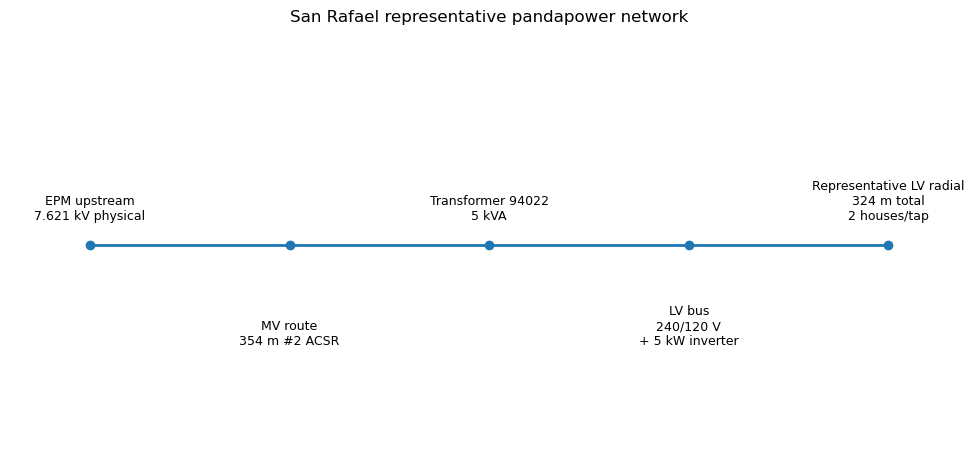

In [10]:
# ============================================================
# 12. REPRESENTATIVE NETWORK TOPOLOGY
# ============================================================

reference_net = build_group_network(4)

topology_rows = []

for idx, row in reference_net.bus.iterrows():
    topology_rows.append({
        "element": "bus",
        "name": row["name"],
        "index": idx,
    })

for idx, row in reference_net.line.iterrows():
    topology_rows.append({
        "element": "line",
        "name": row["name"],
        "index": idx,
    })

for idx, row in reference_net.trafo.iterrows():
    topology_rows.append({
        "element": "transformer",
        "name": row["name"],
        "index": idx,
    })

display(pd.DataFrame(topology_rows))

fig, ax = plt.subplots(figsize=(10, 4.8))

x = [0, 1, 2, 3, 4]
labels = [
    "EPM upstream\n7.621 kV physical",
    f"MV route\n{MV_ROUTE_M:.0f} m #2 ACSR",
    "Transformer 94022\n5 kVA",
    "LV bus\n240/120 V\n+ 5 kW inverter",
    f"Representative LV radial\n{LV_ROUTE_M:.0f} m total\n2 houses/tap",
]

ax.plot(x, [0]*len(x), marker="o", linewidth=2)

for xi, label in zip(x, labels):
    ax.annotate(
        label,
        (xi, 0),
        xytext=(0, 18 if xi % 2 == 0 else -72),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_xlim(-0.4, 4.4)
ax.set_ylim(-1.0, 1.0)
ax.axis("off")
ax.set_title(
    "San Rafael representative pandapower network"
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "pandapower_reference_topology.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 13. One-shot validation of the balanced equivalent

The √3-voltage / 3×-power / loop-impedance construction is checked once against a direct single-phase voltage-drop calculation. This is a diagnostic of the representation, not a new operating scenario.

A single 0.5 kW household is placed at the end of the fixed 324.5 m LV route. The manual calculation uses the solved transformer-LV voltage as its sending-end voltage and compares the expected \(I(R\cos\phi + X\sin\phi)\) drop with the pandapower receiving-end voltage.


In [11]:
# ============================================================
# 13. SINGLE-PHASE EQUIVALENT VALIDATION
# ============================================================

def validate_single_phase_equivalent(
    test_load_kw=0.5,
    load_pf=LOAD_POWER_FACTOR,
):
    net = build_group_network(
        1,
        route_mode="fixed",
    )

    set_operating_point(
        net,
        house_loads_kw=np.array(
            [float(test_load_kw)]
        ),
        inverter_ac_kw=0.0,
        load_pf=load_pf,
    )

    solve_network(net)

    source_bus = (
        net._san_rafael[
            "trafo_lv_bus"
        ]
    )
    end_bus = (
        net._san_rafael[
            "lv_bus_indices"
        ][-1]
    )

    source_vm_pu = float(
        net.res_bus.at[
            source_bus,
            "vm_pu",
        ]
    )
    pp_end_vm_pu = float(
        net.res_bus.at[
            end_bus,
            "vm_pu",
        ]
    )

    phi = math.acos(
        float(load_pf)
    )

    current_a = (
        float(test_load_kw)
        * 1000.0
        / (
            LV_PHYSICAL_KV
            * 1000.0
            * float(load_pf)
        )
    )

    route_km = (
        float(
            net._san_rafael[
                "lv_total_route_m"
            ]
        )
        / 1000.0
    )

    r_loop_ohm = (
        LV_R_LOOP_OHM_PER_KM
        * route_km
    )
    x_loop_ohm = (
        LV_X_LOOP_OHM_PER_KM
        * route_km
    )

    delta_v = current_a * (
        r_loop_ohm
        * math.cos(phi)
        + x_loop_ohm
        * math.sin(phi)
    )

    physical_source_v = (
        source_vm_pu
        * LV_PHYSICAL_KV
        * 1000.0
    )

    manual_end_vm_pu = (
        physical_source_v
        - delta_v
    ) / (
        LV_PHYSICAL_KV
        * 1000.0
    )

    difference_pct = (
        100.0
        * (
            pp_end_vm_pu
            - manual_end_vm_pu
        )
        / manual_end_vm_pu
    )

    result = pd.DataFrame([{
        "test_load_kw":
            float(test_load_kw),
        "load_power_factor":
            float(load_pf),
        "physical_current_a":
            current_a,
        "source_lv_vm_pu":
            source_vm_pu,
        "manual_end_vm_pu":
            manual_end_vm_pu,
        "pandapower_end_vm_pu":
            pp_end_vm_pu,
        "difference_pct":
            difference_pct,
        "validation_note":
            (
                "First-order single-phase I*Z comparison; "
                "small residual difference is expected because "
                "pandapower solves the nonlinear AC power flow."
            ),
    }])

    return result


if RUN_EQUIVALENT_VALIDATION:
    equivalent_validation = (
        validate_single_phase_equivalent()
    )

    display(
        equivalent_validation.round(6)
    )

    equivalent_validation.to_csv(
        RESULTS_DIR
        / "single_phase_equivalent_validation.csv",
        index=False,
    )


,test_load_kw,load_power_factor,physical_current_a,source_lv_vm_pu,manual_end_vm_pu,pandapower_end_vm_pu,difference_pct,validation_note
0,0.5,0.9,2.314815,0.996669,0.992755,0.992725,-0.002981,First-order single-phase I*Z comparison; small...


## 14. Annual four-house simulation

The 8,760 hourly operating points are run through the four-house network.

Each house keeps its own stochastic demand profile, so the radial feeder sees both aggregate demand variability and unequal loading between connection points.

In [12]:
# ============================================================
# 15. ANNUAL 4-HOUSE NASA -> PANDAPOWER RUN
# ============================================================

annual_net = build_group_network(4)

annual_rows = []

for row in annual_inputs.itertuples(index=False):
    house_loads_kw = np.array([
        getattr(row, f"house_{h}_kw")
        for h in range(1, 5)
    ], dtype=float)

    set_operating_point(
        annual_net,
        inverter_ac_kw=row.nasa_pv_ac_kw,
        house_loads_kw=house_loads_kw,
    )

    solve_network(annual_net)

    result = extract_snapshot_results(
        annual_net,
        scenario="NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE",
        total_load_kw=float(house_loads_kw.sum()),
        inverter_ac_kw=row.nasa_pv_ac_kw,
    )

    result["timestamp"] = row.timestamp
    result["nasa_ghi_wm2"] = row.ALLSKY_SFC_SW_DWN
    result["nasa_dni_wm2"] = row.ALLSKY_SFC_SW_DNI
    result["poa_global_wm2"] = row.poa_global_wm2
    result["nasa_pv_dc_kw"] = row.nasa_pv_dc_kw
    result["nasa_pv_ac_kw"] = row.nasa_pv_ac_kw

    annual_rows.append(result)

annual_results = pd.DataFrame(annual_rows)

annual_results.to_csv(
    RESULTS_DIR / "nasa_annual_4hh_pandapower_results.csv",
    index=False,
)

display(annual_results.head())
print("Rows:", len(annual_results))

,scenario,houses,route_mode,lv_total_route_m,load_kw,inverter_ac_kw,inverter_q_kvar,net_demand_before_losses_kw,pcc_import_physical_kw,transformer_loading_pct,transformer_lv_current_a,max_mv_line_loading_pct,max_lv_line_loading_pct,min_lv_vm_pu,max_lv_vm_pu,lv_drop_screen_ok,lv_rise_screen_ok,transformer_nominal_ok,line_loading_ok,timestamp,nasa_ghi_wm2,nasa_dni_wm2,poa_global_wm2,nasa_pv_dc_kw,nasa_pv_ac_kw
0,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,fixed,324.5,0.754533,0.0,0.0,0.754533,0.790349,18.601854,3.522729,0.066328,2.348486,0.990891,0.995143,True,True,True,True,2025-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0
1,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,fixed,324.5,0.600543,0.0,0.0,0.600543,0.634262,15.152650,2.799233,0.054029,1.866156,0.992648,0.996069,True,True,True,True,2025-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0
2,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,fixed,324.5,0.668820,0.0,0.0,0.668820,0.703558,16.682108,3.120317,0.059483,2.080211,0.991672,0.995658,True,True,True,True,2025-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0
3,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,fixed,324.5,0.732057,0.0,0.0,0.732057,0.767568,18.097732,3.417105,0.064530,2.278070,0.991106,0.995278,True,True,True,True,2025-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0
4,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,fixed,324.5,0.624119,0.0,0.0,0.624119,0.658172,15.680131,2.910021,0.055910,1.940014,0.992315,0.995927,True,True,True,True,2025-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0


Rows: 8760


In [13]:
# ============================================================
# 16. NASA ANNUAL 4-HOUSE SUMMARY
# ============================================================

annual_summary = pd.DataFrame([
    {
        "metric": "Minimum LV voltage",
        "value": annual_results["min_lv_vm_pu"].min(),
        "unit": "pu",
    },
    {
        "metric": "Maximum LV voltage",
        "value": annual_results["max_lv_vm_pu"].max(),
        "unit": "pu",
    },
    {
        "metric": "Maximum transformer loading",
        "value": annual_results["transformer_loading_pct"].max(),
        "unit": "%",
    },
    {
        "metric": "Maximum LV line loading",
        "value": annual_results["max_lv_line_loading_pct"].max(),
        "unit": "%",
    },
    {
        "metric": "Maximum MV line loading",
        "value": annual_results["max_mv_line_loading_pct"].max(),
        "unit": "%",
    },
    {
        "metric": "Maximum physical PCC import",
        "value": annual_results["pcc_import_physical_kw"].max(),
        "unit": "kW",
    },
    {
        "metric": "Maximum physical PCC export",
        "value": -annual_results["pcc_import_physical_kw"].min(),
        "unit": "kW",
    },
    {
        "metric": "Maximum NASA-derived inverter AC",
        "value": annual_results["nasa_pv_ac_kw"].max(),
        "unit": "kW",
    },
])

display(annual_summary.round(4))

annual_summary.to_csv(
    RESULTS_DIR / "nasa_annual_4hh_summary.csv",
    index=False,
)

def critical_row_pos(df, column, mode="min"):
    values = pd.to_numeric(
        df[column],
        errors="coerce",
    ).to_numpy(dtype=float)

    if np.isnan(values).all():
        raise ValueError(
            f"Column '{column}' contains no finite values."
        )

    if mode == "min":
        return int(np.nanargmin(values))
    if mode == "max":
        return int(np.nanargmax(values))

    raise ValueError("mode must be 'min' or 'max'")


critical_specs = [
    ("minimum LV voltage", "min_lv_vm_pu", "min"),
    ("maximum LV voltage", "max_lv_vm_pu", "max"),
    ("maximum transformer loading", "transformer_loading_pct", "max"),
    ("maximum LV line loading", "max_lv_line_loading_pct", "max"),
    ("maximum physical PCC export", "pcc_import_physical_kw", "min"),
]

critical_frames = []

for label, column, mode in critical_specs:
    pos = critical_row_pos(
        annual_results,
        column,
        mode,
    )

    row = (
        annual_results.iloc[[pos]]
        .copy()
        .assign(critical_condition=label)
    )

    critical_frames.append(row)

critical_rows = pd.concat(
    critical_frames,
    ignore_index=True,
)

display(
    critical_rows[
        [
            "critical_condition",
            "timestamp",
            "load_kw",
            "nasa_pv_ac_kw",
            "pcc_import_physical_kw",
            "min_lv_vm_pu",
            "max_lv_vm_pu",
            "transformer_loading_pct",
            "max_lv_line_loading_pct",
            "nasa_ghi_wm2",
            "poa_global_wm2",
        ]
    ].round(4)
)

critical_rows.to_csv(
    RESULTS_DIR / "nasa_annual_4hh_critical_snapshots.csv",
    index=False,
)

,metric,value,unit
0,Minimum LV voltage,0.9736,pu
1,Maximum LV voltage,1.0094,pu
2,Maximum transformer loading,61.3215,%
3,Maximum LV line loading,6.8533,%
4,Maximum MV line loading,0.2174,%
5,Maximum physical PCC import,2.2467,kW
6,Maximum physical PCC export,3.0216,kW
7,Maximum NASA-derived inverter AC,3.6576,kW


,critical_condition,timestamp,load_kw,nasa_pv_ac_kw,pcc_import_physical_kw,min_lv_vm_pu,max_lv_vm_pu,transformer_loading_pct,max_lv_line_loading_pct,nasa_ghi_wm2,poa_global_wm2
0,minimum LV voltage,2025-11-29 20:00:00,2.1667,0.0000,2.2467,0.9736,0.9865,50.9661,6.8533,0.00,0.0000
1,maximum LV voltage,2025-01-18 11:00:00,0.4956,3.5823,-3.0216,1.0072,1.0094,61.3215,1.5184,959.42,991.8201
2,maximum transformer loading,2025-01-18 11:00:00,0.4956,3.5823,-3.0216,1.0072,1.0094,61.3215,1.5184,959.42,991.8201
3,maximum LV line loading,2025-11-29 20:00:00,2.1667,0.0000,2.2467,0.9736,0.9865,50.9661,6.8533,0.00,0.0000
4,maximum physical PCC export,2025-01-18 11:00:00,0.4956,3.5823,-3.0216,1.0072,1.0094,61.3215,1.5184,959.42,991.8201


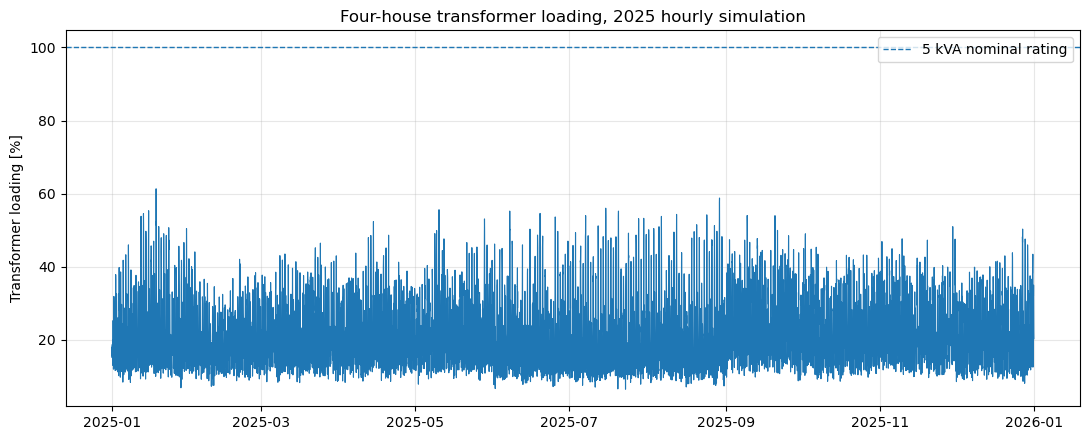

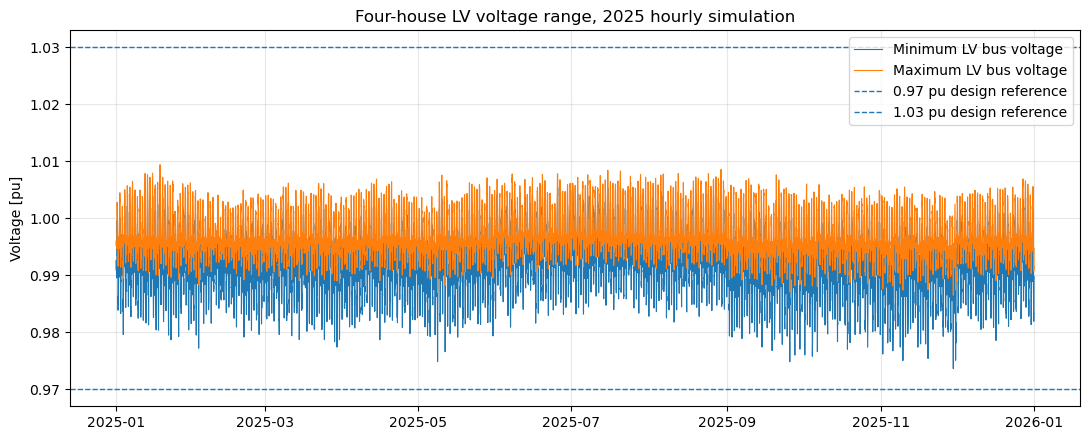

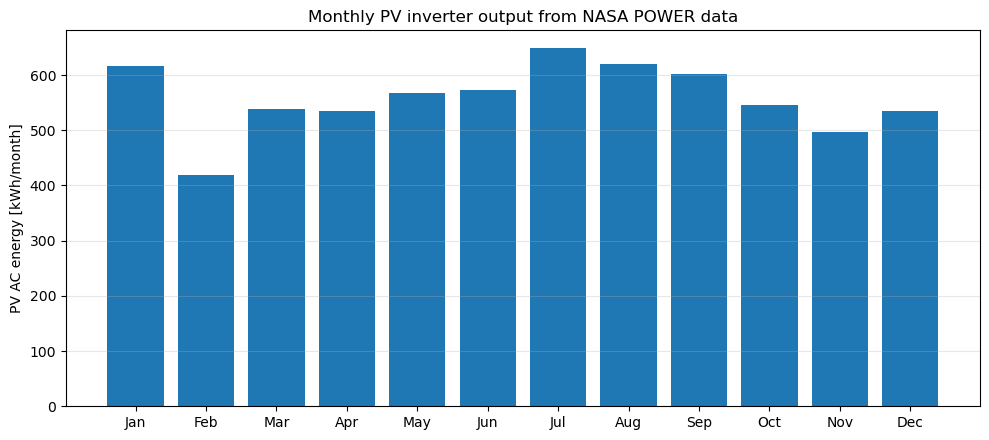

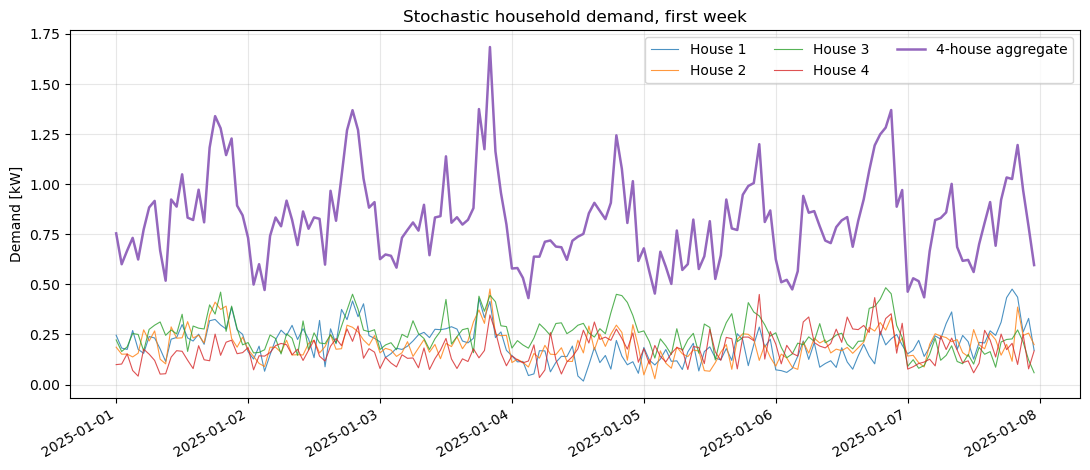

In [14]:
# ============================================================
# 17. NASA ANNUAL REFERENCE PLOTS
# ============================================================

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(
    annual_results["timestamp"],
    annual_results["transformer_loading_pct"],
    linewidth=0.8,
)
ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="5 kVA nominal rating",
)
ax.set_ylabel("Transformer loading [%]")
ax.set_title("Four-house transformer loading, 2025 hourly simulation")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_annual_4hh_transformer_loading.png",
    dpi=180,
)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(
    annual_results["timestamp"],
    annual_results["min_lv_vm_pu"],
    linewidth=0.8,
    label="Minimum LV bus voltage",
)
ax.plot(
    annual_results["timestamp"],
    annual_results["max_lv_vm_pu"],
    linewidth=0.8,
    label="Maximum LV bus voltage",
)
ax.axhline(
    LV_SCREEN_MIN_PU,
    linestyle="--",
    linewidth=1,
    label="0.97 pu design reference",
)
ax.axhline(
    LV_SCREEN_MAX_PU,
    linestyle="--",
    linewidth=1,
    label="1.03 pu design reference",
)
ax.set_ylabel("Voltage [pu]")
ax.set_title("Four-house LV voltage range, 2025 hourly simulation")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_annual_4hh_voltage_envelope.png",
    dpi=180,
)
plt.show()

# Monthly PV energy
monthly_pv = (
    annual_inputs
    .set_index("timestamp")["nasa_pv_ac_kw"]
    .resample("MS")
    .sum()
)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(
    monthly_pv.index.strftime("%b"),
    monthly_pv.values,
)
ax.set_ylabel("PV AC energy [kWh/month]")
ax.set_title("Monthly PV inverter output from NASA POWER data")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_monthly_pv_ac_energy.png",
    dpi=180,
)
plt.show()


week = annual_inputs.iloc[:24 * 7]

fig, ax = plt.subplots(figsize=(11, 4.8))

for house in range(1, 5):
    ax.plot(
        week["timestamp"],
        week[f"house_{house}_kw"],
        linewidth=0.8,
        alpha=0.8,
        label=f"House {house}",
    )

ax.plot(
    week["timestamp"],
    week["load_4hh_kw"],
    linewidth=1.8,
    label="4-house aggregate",
)

ax.set_ylabel("Demand [kW]")
ax.set_title("Stochastic household demand, first week")
ax.grid(True, alpha=0.3)
ax.legend(ncol=3)
fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "stochastic_household_demand_first_week.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()


### Maximum-export day

The daily plot below shows the load, PV output and PCC power on the day with the highest annual reverse flow. Positive PCC power is grid import and negative PCC power is export.

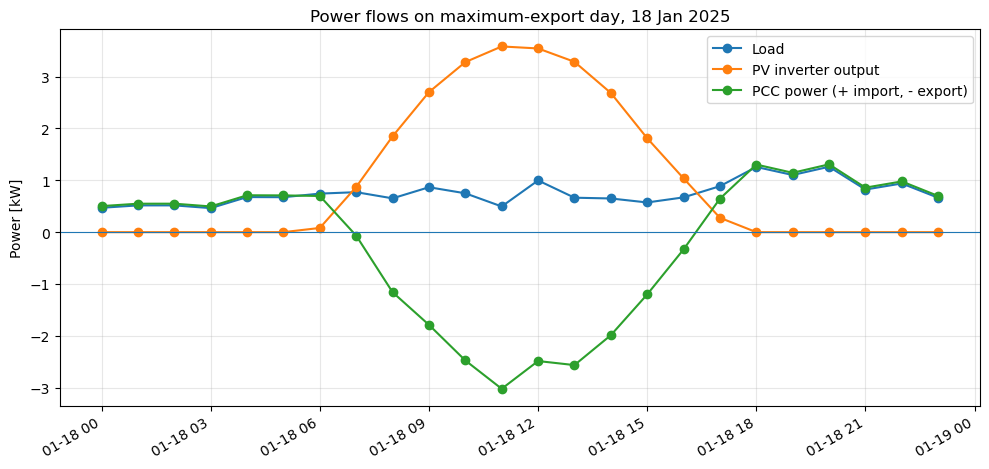

In [15]:
# Day containing the maximum annual reverse flow
max_export_pos = int(
    np.nanargmin(
        annual_results["pcc_import_physical_kw"].to_numpy(dtype=float)
    )
)

max_export_timestamp = pd.Timestamp(
    annual_results.iloc[max_export_pos]["timestamp"]
)

day_start = max_export_timestamp.normalize()
day_end = day_start + pd.Timedelta(days=1)

day_results = annual_results[
    (annual_results["timestamp"] >= day_start)
    & (annual_results["timestamp"] < day_end)
].copy()

fig, ax = plt.subplots(figsize=(10, 4.8))

ax.plot(
    day_results["timestamp"],
    day_results["load_kw"],
    marker="o",
    label="Load",
)

ax.plot(
    day_results["timestamp"],
    day_results["nasa_pv_ac_kw"],
    marker="o",
    label="PV inverter output",
)

ax.plot(
    day_results["timestamp"],
    day_results["pcc_import_physical_kw"],
    marker="o",
    label="PCC power (+ import, - export)",
)

ax.axhline(0.0, linewidth=0.8)
ax.set_ylabel("Power [kW]")
ax.set_title(
    f"Power flows on maximum-export day, {day_start:%d %b %Y}"
)
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "nasa_max_export_day_power_flows.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 18. Four to eight-house sensitivity

The stochastic profiles are the primary demand input.

For each group size, the group consists of houses 1 through N from the same reproducible profile set.

- **Peak demand, no PV:** actual maximum of the N-house stochastic aggregate.
- **NASA annual maximum export:** hour with the largest `PV output - stochastic group load`.
- **Inverter stress:** 4.0, 4.5 and 5.0 kW at the minimum daytime stochastic load for that group.

In [16]:
# ============================================================
# 19. BUILD 4–8-HOUSE STOCHASTIC SCENARIO MATRIX
# ============================================================

scenario_rows = []

for houses in HOUSE_COUNTS:
    group_col = f"load_{houses}hh_kw"

    max_load_idx = annual_inputs[group_col].idxmax()
    max_load_row = annual_inputs.loc[max_load_idx]

    scenario_rows.append({
        "houses": houses,
        "scenario": "MAX_LOAD_NO_DER",
        "timestamp": max_load_row["timestamp"],
        "load_kw": float(max_load_row[group_col]),
        "inverter_ac_kw": 0.0,
    })

    export_margin = (
        annual_inputs["nasa_pv_ac_kw"]
        - annual_inputs[group_col]
    )

    nasa_export_idx = export_margin.idxmax()
    nasa_export_row = annual_inputs.loc[nasa_export_idx]

    scenario_rows.append({
        "houses": houses,
        "scenario": "NASA_MAX_EXPORT_HOURLY",
        "timestamp": nasa_export_row["timestamp"],
        "load_kw": float(nasa_export_row[group_col]),
        "inverter_ac_kw": float(
            nasa_export_row["nasa_pv_ac_kw"]
        ),
    })

    daytime = annual_inputs.loc[
        annual_inputs["timestamp"].dt.hour.between(10, 14)
    ]

    min_day_idx = daytime[group_col].idxmin()
    min_day_row = annual_inputs.loc[min_day_idx]

    for inverter_kw in CLEAR_SKY_INVERTER_KW:
        scenario_rows.append({
            "houses": houses,
            "scenario": f"CLEAR_SKY_{inverter_kw:.1f}KW",
            "timestamp": min_day_row["timestamp"],
            "load_kw": float(min_day_row[group_col]),
            "inverter_ac_kw": inverter_kw,
        })

scenario_matrix = pd.DataFrame(scenario_rows)
display(scenario_matrix.round(4))

,houses,scenario,timestamp,load_kw,inverter_ac_kw
0,4,MAX_LOAD_NO_DER,2025-11-29 20:00:00,2.1667,0.0000
1,4,NASA_MAX_EXPORT_HOURLY,2025-01-18 11:00:00,0.4956,3.5823
2,4,CLEAR_SKY_4.0KW,2025-06-25 13:00:00,0.3207,4.0000
3,4,CLEAR_SKY_4.5KW,2025-06-25 13:00:00,0.3207,4.5000
4,4,CLEAR_SKY_5.0KW,2025-06-25 13:00:00,0.3207,5.0000
5,5,MAX_LOAD_NO_DER,2025-09-27 19:00:00,2.5193,0.0000
6,5,NASA_MAX_EXPORT_HOURLY,2025-08-29 12:00:00,0.7507,3.5972
7,5,CLEAR_SKY_4.0KW,2025-07-11 10:00:00,0.4974,4.0000
8,5,CLEAR_SKY_4.5KW,2025-07-11 10:00:00,0.4974,4.5000
9,5,CLEAR_SKY_5.0KW,2025-07-11 10:00:00,0.4974,5.0000


In [17]:
# ============================================================
# 20. RUN 4–8-HOUSE STOCHASTIC GROUPING SENSITIVITY
# ============================================================

def household_loads_at_timestamp(timestamp, houses):
    row = annual_inputs.loc[
        annual_inputs["timestamp"] == pd.Timestamp(timestamp)
    ]

    if row.empty:
        raise KeyError(f"Timestamp not found: {timestamp}")

    row = row.iloc[0]

    return np.array([
        row[f"house_{h}_kw"]
        for h in range(1, houses + 1)
    ], dtype=float)


grouping_results = []

for row in scenario_matrix.itertuples(index=False):
    house_loads_kw = household_loads_at_timestamp(
        row.timestamp,
        row.houses,
    )

    _, result = run_snapshot(
        houses=row.houses,
        scenario=row.scenario,
        inverter_ac_kw=row.inverter_ac_kw,
        house_loads_kw=house_loads_kw,
    )

    result["timestamp"] = row.timestamp
    result["peak_house_load_kw"] = float(
        house_loads_kw.max()
    )

    grouping_results.append(result)

grouping_results = pd.DataFrame(grouping_results)

display(
    grouping_results[
        [
            "scenario",
            "houses",
            "timestamp",
            "load_kw",
            "peak_house_load_kw",
            "inverter_ac_kw",
            "pcc_import_physical_kw",
            "transformer_loading_pct",
            "transformer_lv_current_a",
            "max_mv_line_loading_pct",
            "max_lv_line_loading_pct",
            "min_lv_vm_pu",
            "max_lv_vm_pu",
            "transformer_nominal_ok",
            "lv_drop_screen_ok",
            "lv_rise_screen_ok",
        ]
    ].round(4)
)

grouping_results.to_csv(
    RESULTS_DIR / "nasa_grouping_4_to_8_house_results.csv",
    index=False,
)

,scenario,houses,timestamp,load_kw,peak_house_load_kw,inverter_ac_kw,pcc_import_physical_kw,transformer_loading_pct,transformer_lv_current_a,max_mv_line_loading_pct,max_lv_line_loading_pct,min_lv_vm_pu,max_lv_vm_pu,transformer_nominal_ok,lv_drop_screen_ok,lv_rise_screen_ok
0,MAX_LOAD_NO_DER,4,2025-11-29 20:00:00,2.1667,0.6061,0.0000,2.2467,50.9661,10.2800,0.1817,6.8533,0.9736,0.9865,True,True,True
1,NASA_MAX_EXPORT_HOURLY,4,2025-01-18 11:00:00,0.4956,0.2448,3.5823,-3.0216,61.3215,12.7753,0.2174,1.5184,1.0072,1.0094,True,True,True
2,CLEAR_SKY_4.0KW,4,2025-06-25 13:00:00,0.3207,0.1261,4.0000,-3.6009,72.7760,15.1617,0.2579,0.9799,1.0098,1.0119,True,True,True
3,CLEAR_SKY_4.5KW,4,2025-06-25 13:00:00,0.3207,0.1261,4.5000,-4.0872,82.5114,17.1899,0.2926,0.9782,1.0115,1.0136,True,True,True
4,CLEAR_SKY_5.0KW,4,2025-06-25 13:00:00,0.3207,0.1261,5.0000,-4.5720,92.2167,19.2118,0.3272,0.9766,1.0132,1.0153,True,True,True
5,MAX_LOAD_NO_DER,5,2025-09-27 19:00:00,2.5193,0.6369,0.0000,2.6101,59.0865,11.9729,0.2107,7.9819,0.9714,0.9843,True,True,True
6,NASA_MAX_EXPORT_HOURLY,5,2025-08-29 12:00:00,0.7507,0.1872,3.5972,-2.7848,56.8919,11.8525,0.2021,2.3049,1.0045,1.0080,True,True,True
7,CLEAR_SKY_4.0KW,5,2025-07-11 10:00:00,0.4974,0.1564,4.0000,-3.4282,69.4470,14.4681,0.2463,1.5210,1.0089,1.0108,True,True,True
8,CLEAR_SKY_4.5KW,5,2025-07-11 10:00:00,0.4974,0.1564,4.5000,-3.9151,79.1849,16.4969,0.2809,1.5185,1.0106,1.0126,True,True,True
9,CLEAR_SKY_5.0KW,5,2025-07-11 10:00:00,0.4974,0.1564,5.0000,-4.4004,88.8953,18.5199,0.3155,1.5159,1.0123,1.0143,True,True,True


### Monte Carlo percentile demand snapshots

If PyPSA v18 has generated `monte_carlo_p95_load_snapshots.csv`, the grid model evaluates those actual household vectors in addition to the fixed-seed reference cases. The selected point is the realization and timestamp nearest the requested percentile of annual coincident maxima, so the per-house loading pattern is preserved.

This addresses seed sensitivity in the peak-demand handoff. It does not make HOMER's independent hourly noise a measured demand model.


### Monte Carlo percentile export snapshot

If PyPSA v18 has generated `monte_carlo_p95_export_snapshot.csv`, v5 evaluates the selected P95 reverse-flow operating point separately from the chronological reference case. The snapshot preserves the actual per-house demand values and inverter AC output at the selected export-critical hour.

This is the operator-facing reverse-flow planning case. The annual handoff remains useful for chronological behavior, but its reference-realization export peak is not treated as the P95 planning value.


In [18]:
# ============================================================
# 20A. MONTE CARLO P95 DEMAND SNAPSHOTS
# ============================================================

mc_p95_grid_results = pd.DataFrame()

if (
    RUN_MC_P95_SNAPSHOTS
    and not mc_p95_snapshots.empty
):
    rows = []

    for record in mc_p95_snapshots.itertuples(
        index=False
    ):
        houses = int(record.houses)

        if houses not in HOUSE_COUNTS:
            continue

        house_loads_kw = np.array([
            float(
                getattr(
                    record,
                    f"house_{h}_kw",
                )
            )
            for h in range(
                1,
                houses + 1,
            )
        ])

        _, result = run_snapshot(
            houses=houses,
            scenario="MC_P95_MAX_LOAD_NO_DER",
            inverter_ac_kw=0.0,
            house_loads_kw=house_loads_kw,
            route_mode="fixed",
        )

        result.update({
            "selected_seed":
                int(record.selected_seed),
            "selected_realization":
                int(
                    record.selected_realization
                ),
            "selected_timestamp":
                pd.Timestamp(
                    record.selected_timestamp
                ),
            "target_percentile_peak_kw":
                float(
                    record.target_percentile_peak_kw
                ),
            "selected_peak_kw":
                float(
                    record.selected_peak_kw
                ),
            "percentile":
                float(record.percentile),
        })

        rows.append(result)

    mc_p95_grid_results = pd.DataFrame(
        rows
    )

    display(
        mc_p95_grid_results[
            [
                "houses",
                "percentile",
                "selected_timestamp",
                "selected_peak_kw",
                "transformer_loading_pct",
                "max_lv_line_loading_pct",
                "min_lv_vm_pu",
                "transformer_nominal_ok",
                "lv_drop_screen_ok",
            ]
        ].round(4)
    )

    mc_p95_grid_results.to_csv(
        RESULTS_DIR
        / "mc_p95_demand_pandapower_results.csv",
        index=False,
    )

    reference_peak_rows = (
        grouping_results[
            grouping_results["scenario"]
            == "MAX_LOAD_NO_DER"
        ][
            [
                "houses",
                "load_kw",
            ]
        ]
        .rename(
            columns={
                "load_kw":
                    "reference_seed_peak_kw"
            }
        )
    )

    reference_vs_p95_peak = (
        reference_peak_rows
        .merge(
            mc_p95_grid_results[
                [
                    "houses",
                    "selected_peak_kw",
                    "target_percentile_peak_kw",
                    "percentile",
                    "selected_timestamp",
                ]
            ],
            on="houses",
            how="inner",
            validate="one_to_one",
        )
        .rename(
            columns={
                "selected_peak_kw":
                    "p95_selected_peak_kw",
                "target_percentile_peak_kw":
                    "p95_target_peak_kw",
            }
        )
    )

    reference_vs_p95_peak[
        "p95_vs_reference_pct"
    ] = (
        100.0
        * (
            reference_vs_p95_peak[
                "p95_selected_peak_kw"
            ]
            / reference_vs_p95_peak[
                "reference_seed_peak_kw"
            ]
            - 1.0
        )
    )

    display(
        reference_vs_p95_peak.round(4)
    )

    reference_vs_p95_peak.to_csv(
        RESULTS_DIR
        / "reference_vs_p95_planning_peak.csv",
        index=False,
    )
else:
    print(
        "Monte Carlo P95 snapshot file not available. "
        "Reference-seed grouping cases remain available."
    )


# ============================================================
# 20B. MONTE CARLO P95 REVERSE-FLOW SNAPSHOT
# ============================================================

mc_p95_export_grid_result = pd.DataFrame()

if (
    RUN_MC_P95_EXPORT_SNAPSHOT
    and not mc_p95_export_snapshot.empty
):
    if len(mc_p95_export_snapshot) != 1:
        raise ValueError(
            "Expected exactly one P95 export planning snapshot."
        )

    record = mc_p95_export_snapshot.iloc[0]

    houses = 4

    house_loads_kw = np.array([
        float(
            record[
                f"house_{h}_kw"
            ]
        )
        for h in range(
            1,
            houses + 1,
        )
    ])

    inverter_ac_kw = float(
        record[
            "inverter_ac_output_kw"
        ]
    )

    _, export_result = run_snapshot(
        houses=houses,
        scenario="MC_P95_EXPORT_NASA_GHI_ERBS",
        inverter_ac_kw=inverter_ac_kw,
        house_loads_kw=house_loads_kw,
        route_mode="fixed",
    )

    export_result.update({
        "percentile":
            float(
                record[
                    "percentile"
                ]
            ),
        "target_percentile_export_kw":
            float(
                record[
                    "target_percentile_export_kw"
                ]
            ),
        "selected_peak_export_kw":
            float(
                record[
                    "selected_peak_export_kw"
                ]
            ),
        "selected_seed":
            int(
                record[
                    "selected_seed"
                ]
            ),
        "selected_realization":
            int(
                record[
                    "selected_realization"
                ]
            ),
        "selected_timestamp":
            pd.Timestamp(
                record[
                    "selected_timestamp"
                ]
            ),
        "pypsa_inverter_ac_output_kw":
            inverter_ac_kw,
        "pypsa_selected_load_kw":
            float(
                record[
                    "load_kw"
                ]
            ),
        "pypsa_pcc_export_kw":
            float(
                record[
                    "pcc_export_kw"
                ]
            ),
    })

    mc_p95_export_grid_result = (
        pd.DataFrame(
            [export_result]
        )
    )

    display(
        mc_p95_export_grid_result[
            [
                "houses",
                "percentile",
                "selected_timestamp",
                "pypsa_pcc_export_kw",
                "inverter_ac_kw",
                "load_kw",
                "transformer_loading_pct",
                "max_lv_line_loading_pct",
                "max_lv_vm_pu",
                "transformer_nominal_ok",
                "lv_rise_screen_ok",
            ]
        ].round(4)
    )

    mc_p95_export_grid_result.to_csv(
        RESULTS_DIR
        / "mc_p95_export_pandapower_result.csv",
        index=False,
    )

    reference_export_kw = np.nan

    if (
        not handoff.empty
        and "pcc_import_positive_kw"
        in handoff.columns
    ):
        reference_export_kw = float(
            -handoff[
                "pcc_import_positive_kw"
            ].min()
        )

    reference_vs_p95_export = pd.DataFrame([
        {
            "reference_realization_peak_export_kw":
                reference_export_kw,
            "p95_target_export_kw":
                float(
                    record[
                        "target_percentile_export_kw"
                    ]
                ),
            "p95_selected_export_kw":
                float(
                    record[
                        "selected_peak_export_kw"
                    ]
                ),
            "p95_vs_reference_pct":
                (
                    100.0
                    * (
                        float(
                            record[
                                "selected_peak_export_kw"
                            ]
                        )
                        / reference_export_kw
                        - 1.0
                    )
                    if (
                        pd.notna(
                            reference_export_kw
                        )
                        and reference_export_kw > 0
                    )
                    else np.nan
                ),
            "selected_timestamp":
                pd.Timestamp(
                    record[
                        "selected_timestamp"
                    ]
                ),
        }
    ])

    display(
        reference_vs_p95_export.round(4)
    )

    reference_vs_p95_export.to_csv(
        RESULTS_DIR
        / "reference_vs_p95_export.csv",
        index=False,
    )

else:
    print(
        "Monte Carlo P95 export snapshot not available. "
        "The chronological reference export case remains available, "
        "but it should not be presented as a percentile planning limit."
    )


,houses,percentile,selected_timestamp,selected_peak_kw,transformer_loading_pct,max_lv_line_loading_pct,min_lv_vm_pu,transformer_nominal_ok,lv_drop_screen_ok
0,4,95.0,2025-09-18 19:00:00,2.3120,54.3773,7.3276,0.9715,True,True
1,5,95.0,2025-09-27 19:00:00,2.7731,65.0086,8.8049,0.9692,True,False
2,6,95.0,2025-11-04 20:00:00,3.2285,75.8491,10.3115,0.9624,True,False
3,7,95.0,2025-09-18 20:00:00,3.6766,86.3399,11.7690,0.9600,True,False
4,8,95.0,2025-10-15 19:00:00,4.1036,96.7951,13.2219,0.9530,True,False


,houses,reference_seed_peak_kw,p95_selected_peak_kw,p95_target_peak_kw,percentile,selected_timestamp,p95_vs_reference_pct
0,4,2.1667,2.3120,2.3121,95.0,2025-09-18 19:00:00,6.7056
1,5,2.5193,2.7731,2.7732,95.0,2025-09-27 19:00:00,10.0741
2,6,2.9979,3.2285,3.2294,95.0,2025-11-04 20:00:00,7.6918
3,7,3.7174,3.6766,3.6768,95.0,2025-09-18 20:00:00,-1.0967
4,8,4.1833,4.1036,4.1037,95.0,2025-10-15 19:00:00,-1.9063


,houses,percentile,selected_timestamp,pypsa_pcc_export_kw,inverter_ac_kw,load_kw,transformer_loading_pct,max_lv_line_loading_pct,max_lv_vm_pu,transformer_nominal_ok,lv_rise_screen_ok
0,4,95.0,2025-07-07 11:00:00,2.9315,3.4336,0.5022,58.2898,1.5396,1.0089,True,True


,reference_realization_peak_export_kw,p95_target_export_kw,p95_selected_export_kw,p95_vs_reference_pct,selected_timestamp
0,2.5313,2.9301,2.9315,15.8088,2025-07-07 11:00:00


### Inverter reactive-power sensitivity

Unity power factor remains the base case. The optional sensitivity below asks only whether reactive-power absorption would materially reduce voltage rise at the four-house NASA maximum-export condition. The 0.98 and 0.95 power-factor cases are illustrative screening cases, not claimed inverter settings.


In [19]:
# ============================================================
# 20B. INVERTER REACTIVE-POWER SENSITIVITY
# ============================================================

q_sensitivity_results = pd.DataFrame()

if RUN_INVERTER_Q_SENSITIVITY:
    export_row = (
        grouping_results[
            (grouping_results["houses"] == 4)
            & (
                grouping_results["scenario"]
                == "NASA_MAX_EXPORT_HOURLY"
            )
        ]
        .iloc[0]
    )

    house_loads_kw = (
        household_loads_at_timestamp(
            export_row["timestamp"],
            4,
        )
    )

    rows = []

    for pf in Q_SENSITIVITY_POWER_FACTORS:
        pf = float(pf)

        if not (0 < pf <= 1):
            raise ValueError(
                "Q-sensitivity power factor must be in (0, 1]."
            )

        p_kw = float(
            export_row[
                "inverter_ac_kw"
            ]
        )

        q_absorb_kvar = (
            0.0
            if np.isclose(pf, 1.0)
            else -p_kw
            * math.tan(
                math.acos(pf)
            )
        )

        _, result = run_snapshot(
            houses=4,
            scenario=(
                f"NASA_MAX_EXPORT_PF_{pf:.2f}_ABSORBING"
            ),
            inverter_ac_kw=p_kw,
            inverter_q_kvar=q_absorb_kvar,
            house_loads_kw=house_loads_kw,
            route_mode="fixed",
        )

        result["power_factor"] = pf
        result["timestamp"] = (
            export_row["timestamp"]
        )

        rows.append(result)

    q_sensitivity_results = pd.DataFrame(
        rows
    )

    display(
        q_sensitivity_results[
            [
                "power_factor",
                "inverter_ac_kw",
                "inverter_q_kvar",
                "transformer_loading_pct",
                "max_lv_vm_pu",
                "lv_rise_screen_ok",
            ]
        ].round(4)
    )

    q_sensitivity_results.to_csv(
        RESULTS_DIR
        / "inverter_q_sensitivity_max_export.csv",
        index=False,
    )


,power_factor,inverter_ac_kw,inverter_q_kvar,transformer_loading_pct,max_lv_vm_pu,lv_rise_screen_ok
0,1.00,3.5823,0.0000,61.3215,1.0094,True
1,0.98,3.5823,-0.7274,64.5191,1.0059,True
2,0.95,3.5823,-1.1775,68.1964,1.0038,True


### Four-house transformer loading by operating condition

The transformer loading values below refer to different operating conditions:

- **Peak demand, no PV:** forward power flow from the grid to the houses
- **NASA annual max export:** the highest reverse-flow hour in the 2025 NASA series
- **5 kW inverter stress:** full inverter output at minimum daytime load

The annual maximum transformer loading is therefore not expected to equal the peak-demand loading.

In [20]:
four_house_case_comparison = (
    grouping_results[
        (grouping_results["houses"] == 4)
        & grouping_results["scenario"].isin([
            "MAX_LOAD_NO_DER",
            "NASA_MAX_EXPORT_HOURLY",
            "CLEAR_SKY_5.0KW",
        ])
    ]
    .copy()
)

four_house_case_comparison["case"] = (
    four_house_case_comparison["scenario"].map({
        "MAX_LOAD_NO_DER": "Peak demand, no PV",
        "NASA_MAX_EXPORT_HOURLY": "NASA annual max export",
        "CLEAR_SKY_5.0KW": "5 kW inverter stress",
    })
)

display(
    four_house_case_comparison[
        [
            "case",
            "load_kw",
            "inverter_ac_kw",
            "pcc_import_physical_kw",
            "transformer_loading_pct",
            "min_lv_vm_pu",
            "max_lv_vm_pu",
        ]
    ].round(4)
)

,case,load_kw,inverter_ac_kw,pcc_import_physical_kw,transformer_loading_pct,min_lv_vm_pu,max_lv_vm_pu
0,"Peak demand, no PV",2.1667,0.0000,2.2467,50.9661,0.9736,0.9865
1,NASA annual max export,0.4956,3.5823,-3.0216,61.3215,1.0072,1.0094
4,5 kW inverter stress,0.3207,5.0000,-4.5720,92.2167,1.0132,1.0153


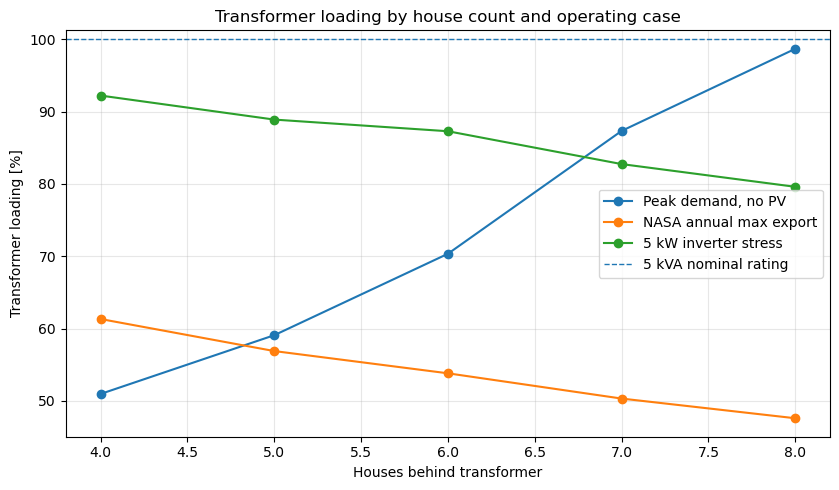

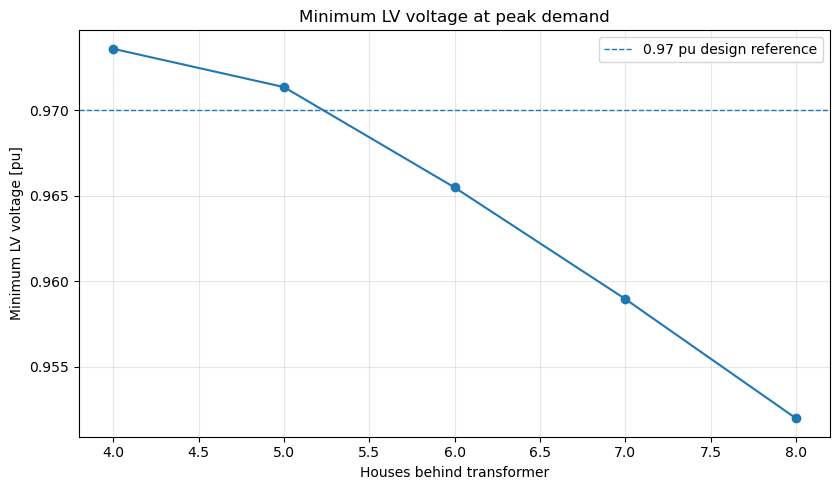

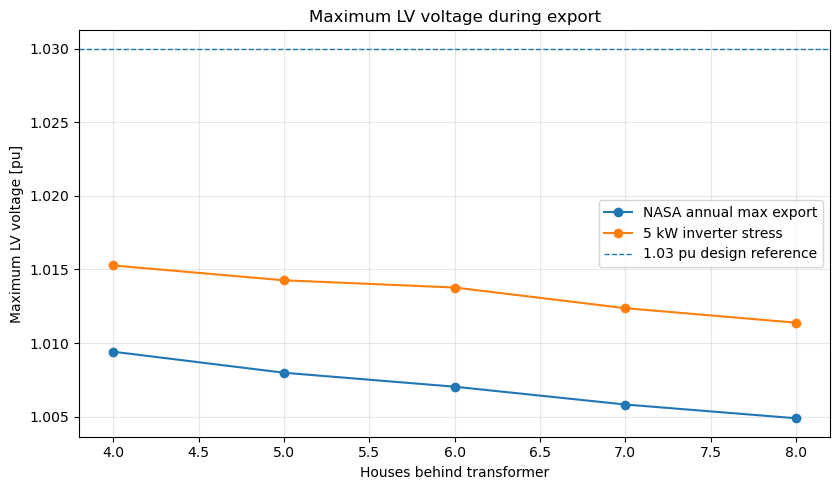

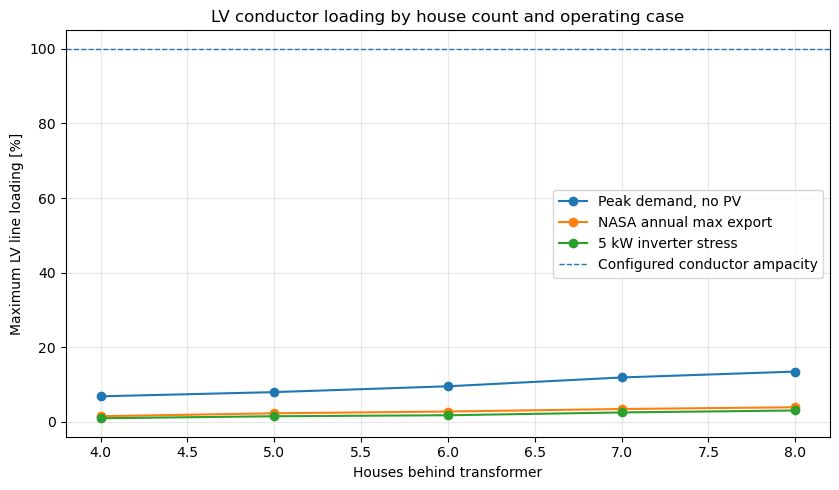

In [21]:
# ============================================================
# 21. GROUPING PLOTS
# ============================================================

def scenario_subset(name):
    return (
        grouping_results[
            grouping_results["scenario"] == name
        ]
        .sort_values("houses")
        .copy()
    )

max_load_results = scenario_subset(
    "MAX_LOAD_NO_DER"
)

nasa_export_results = scenario_subset(
    "NASA_MAX_EXPORT_HOURLY"
)

clear5_results = scenario_subset(
    "CLEAR_SKY_5.0KW"
)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(
    max_load_results["houses"],
    max_load_results["transformer_loading_pct"],
    marker="o",
    label="Peak demand, no PV",
)
ax.plot(
    nasa_export_results["houses"],
    nasa_export_results["transformer_loading_pct"],
    marker="o",
    label="NASA annual max export",
)
ax.plot(
    clear5_results["houses"],
    clear5_results["transformer_loading_pct"],
    marker="o",
    label="5 kW inverter stress",
)
ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="5 kVA nominal rating",
)
ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Transformer loading [%]")
ax.set_title("Transformer loading by house count and operating case")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_grouping_transformer_loading.png",
    dpi=180,
)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(
    max_load_results["houses"],
    max_load_results["min_lv_vm_pu"],
    marker="o",
)
ax.axhline(
    LV_SCREEN_MIN_PU,
    linestyle="--",
    linewidth=1,
    label="0.97 pu design reference",
)
ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Minimum LV voltage [pu]")
ax.set_title("Minimum LV voltage at peak demand")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_grouping_max_load_min_voltage.png",
    dpi=180,
)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(
    nasa_export_results["houses"],
    nasa_export_results["max_lv_vm_pu"],
    marker="o",
    label="NASA annual max export",
)
ax.plot(
    clear5_results["houses"],
    clear5_results["max_lv_vm_pu"],
    marker="o",
    label="5 kW inverter stress",
)
ax.axhline(
    LV_SCREEN_MAX_PU,
    linestyle="--",
    linewidth=1,
    label="1.03 pu design reference",
)
ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Maximum LV voltage [pu]")
ax.set_title("Maximum LV voltage during export")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_grouping_export_max_voltage.png",
    dpi=180,
)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(
    max_load_results["houses"],
    max_load_results["max_lv_line_loading_pct"],
    marker="o",
    label="Peak demand, no PV",
)
ax.plot(
    nasa_export_results["houses"],
    nasa_export_results["max_lv_line_loading_pct"],
    marker="o",
    label="NASA annual max export",
)
ax.plot(
    clear5_results["houses"],
    clear5_results["max_lv_line_loading_pct"],
    marker="o",
    label="5 kW inverter stress",
)
ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="Configured conductor ampacity",
)
ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Maximum LV line loading [%]")
ax.set_title("LV conductor loading by house count and operating case")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_grouping_lv_line_loading.png",
    dpi=180,
)
plt.show()

### LV voltage profile for critical cases

The feeder profile shows where the voltage deviation occurs along the representative LV route. Four cases are shown:

- four houses at peak demand
- four houses at the NASA annual maximum-export condition
- four houses at the 5 kW inverter stress condition
- eight houses at peak demand

This plot is based on the representative radial feeder, not surveyed service-drop geometry.

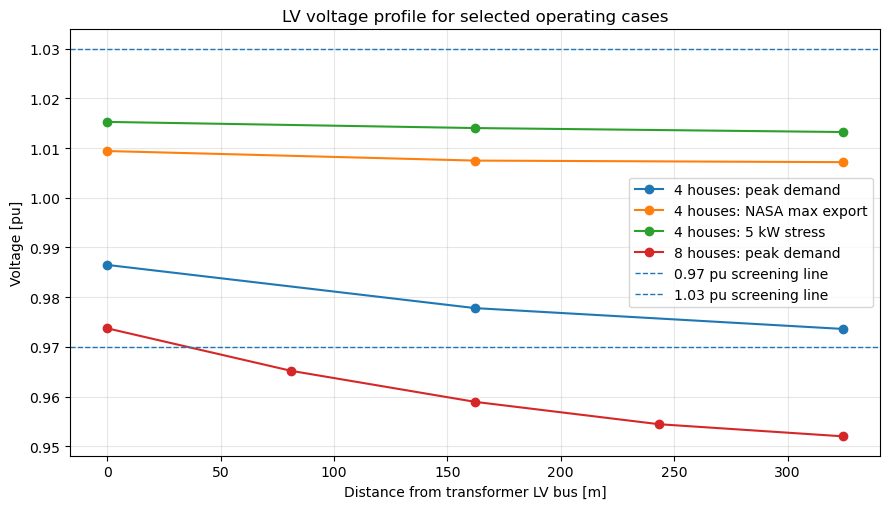

In [22]:
def solve_lv_voltage_profile(
    houses,
    timestamp,
    inverter_ac_kw,
    label,
):
    house_loads_kw = household_loads_at_timestamp(
        timestamp,
        houses,
    )

    net, _ = run_snapshot(
        houses=houses,
        scenario=label,
        inverter_ac_kw=inverter_ac_kw,
        house_loads_kw=house_loads_kw,
    )

    lv_buses = net._san_rafael["lv_bus_indices"]
    n_segments = len(lv_buses) - 1

    distances_m = np.linspace(
        0.0,
        float(
            net._san_rafael[
                "lv_total_route_m"
            ]
        ),
        n_segments + 1,
    )

    vm_pu = (
        net.res_bus.loc[lv_buses, "vm_pu"]
        .to_numpy(dtype=float)
    )

    return pd.DataFrame({
        "distance_m": distances_m,
        "vm_pu": vm_pu,
        "case": label,
    })


def get_group_case(houses, scenario):
    return (
        grouping_results[
            (grouping_results["houses"] == houses)
            & (grouping_results["scenario"] == scenario)
        ]
        .iloc[0]
    )


profile_cases = []

r = get_group_case(4, "MAX_LOAD_NO_DER")
profile_cases.append(
    solve_lv_voltage_profile(
        4,
        r["timestamp"],
        r["inverter_ac_kw"],
        "4 houses: peak demand",
    )
)

r = get_group_case(4, "NASA_MAX_EXPORT_HOURLY")
profile_cases.append(
    solve_lv_voltage_profile(
        4,
        r["timestamp"],
        r["inverter_ac_kw"],
        "4 houses: NASA max export",
    )
)

r = get_group_case(4, "CLEAR_SKY_5.0KW")
profile_cases.append(
    solve_lv_voltage_profile(
        4,
        r["timestamp"],
        r["inverter_ac_kw"],
        "4 houses: 5 kW stress",
    )
)

r = get_group_case(8, "MAX_LOAD_NO_DER")
profile_cases.append(
    solve_lv_voltage_profile(
        8,
        r["timestamp"],
        r["inverter_ac_kw"],
        "8 houses: peak demand",
    )
)

lv_voltage_profiles = pd.concat(
    profile_cases,
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(9, 5.2))

for case_name, df_case in lv_voltage_profiles.groupby("case", sort=False):
    ax.plot(
        df_case["distance_m"],
        df_case["vm_pu"],
        marker="o",
        label=case_name,
    )

ax.axhline(
    LV_SCREEN_MIN_PU,
    linestyle="--",
    linewidth=1,
    label="0.97 pu screening line",
)

ax.axhline(
    LV_SCREEN_MAX_PU,
    linestyle="--",
    linewidth=1,
    label="1.03 pu screening line",
)

ax.set_xlabel("Distance from transformer LV bus [m]")
ax.set_ylabel("Voltage [pu]")
ax.set_title("LV voltage profile for selected operating cases")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "lv_voltage_profile_critical_cases.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 22. Transformer and feeder headroom

Two different questions are kept separate:

- **Fixed existing route:** additional load is placed behind the same represented 324.5 m LV route. This is an electrical headroom test of the existing representation.
- **Expansion sensitivity:** extra taps are allowed to increase total feeder length. This runs only when `EXPANSION_SEGMENT_M` is supplied in the global configuration cell, because no spacing assumption is inserted silently.

The transformer-loading result is largely power-driven. High-house-count voltage results are much more sensitive to the assumed route geometry.


,houses,timestamp,load_kw,peak_house_load_kw,lv_total_route_m,transformer_loading_pct,transformer_lv_current_a,max_lv_line_loading_pct,min_lv_vm_pu
0,1,2025-03-30 19:00:00,0.711,0.711,324.5,17.657,3.325,2.217,0.990
1,2,2025-09-11 20:00:00,1.174,0.615,324.5,28.178,5.526,3.684,0.983
2,3,2025-11-29 20:00:00,1.696,0.606,324.5,40.023,7.998,5.332,0.980
3,4,2025-11-29 20:00:00,2.167,0.606,324.5,50.966,10.280,6.853,0.974
4,5,2025-09-27 19:00:00,2.519,0.637,324.5,59.086,11.973,7.982,0.971
5,6,2025-11-01 19:00:00,2.998,0.569,324.5,70.347,14.320,9.547,0.965
6,7,2025-11-01 19:00:00,3.717,0.720,324.5,87.330,17.860,11.907,0.959
7,8,2025-11-01 19:00:00,4.183,0.720,324.5,98.682,20.226,13.484,0.952
8,9,2025-11-01 19:00:00,4.417,0.720,324.5,104.056,21.346,14.230,0.953
9,10,2025-11-01 19:00:00,4.940,0.720,324.5,116.979,24.039,16.026,0.945


First nominal transformer overload on the fixed existing route in the reference-seed screening sweep: 9 houses. This is not a P95 planning threshold.


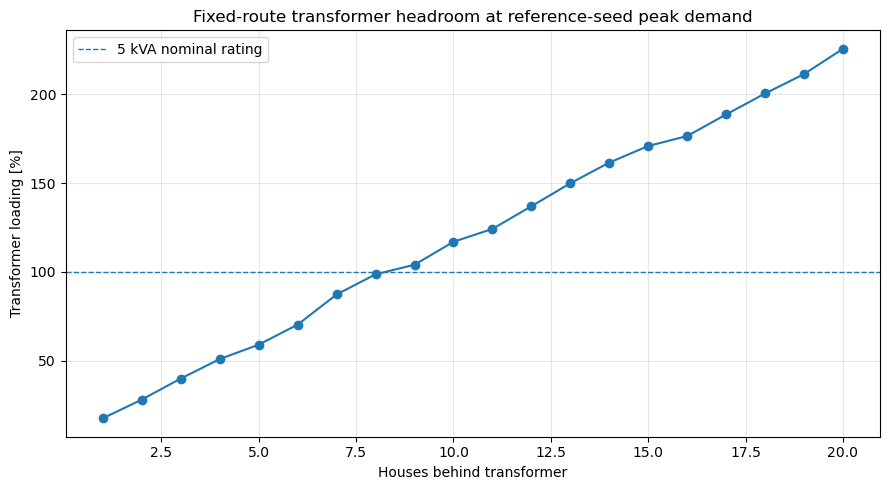

Expansion sensitivity not run. Set EXPANSION_SEGMENT_M in the global configuration cell after choosing a measured or explicitly assumed spacing.


In [23]:
# ============================================================
# 23. TRANSFORMER / FEEDER HEADROOM SWEEPS
# ============================================================

def run_headroom_sweep(
    route_mode="fixed",
    expansion_segment_m=EXPANSION_SEGMENT_M,
):
    rows = []

    for houses in HEADROOM_HOUSE_COUNTS:
        group_col = f"load_{houses}hh_kw"

        if group_col not in annual_inputs.columns:
            break

        peak_idx = annual_inputs[
            group_col
        ].idxmax()
        peak_row = annual_inputs.loc[
            peak_idx
        ]

        house_loads_kw = np.array([
            peak_row[
                f"house_{h}_kw"
            ]
            for h in range(
                1,
                houses + 1,
            )
        ], dtype=float)

        _, result = run_snapshot(
            houses=houses,
            scenario=(
                f"HEADROOM_MAX_LOAD_NO_DER_"
                f"{route_mode.upper()}"
            ),
            inverter_ac_kw=0.0,
            house_loads_kw=house_loads_kw,
            route_mode=route_mode,
            expansion_segment_m=
                expansion_segment_m,
        )

        result["timestamp"] = (
            peak_row["timestamp"]
        )
        result["peak_house_load_kw"] = float(
            house_loads_kw.max()
        )

        rows.append(result)

    return pd.DataFrame(rows)


headroom_results = pd.DataFrame()

if RUN_FIXED_ROUTE_HEADROOM:
    headroom_results = (
        run_headroom_sweep(
            route_mode="fixed",
        )
    )

    first_overload = (
        headroom_results[
            headroom_results[
                "transformer_loading_pct"
            ] > 100
        ].head(1)
    )

    display(
        headroom_results[
            [
                "houses",
                "timestamp",
                "load_kw",
                "peak_house_load_kw",
                "lv_total_route_m",
                "transformer_loading_pct",
                "transformer_lv_current_a",
                "max_lv_line_loading_pct",
                "min_lv_vm_pu",
            ]
        ].round(3)
    )

    if not first_overload.empty:
        n = int(
            first_overload.iloc[0][
                "houses"
            ]
        )

        print(
            "First nominal transformer overload "
            "on the fixed existing route in the "
            "reference-seed screening sweep:",
            n,
            "houses. This is not a P95 planning threshold.",
        )
    else:
        print(
            "No nominal transformer overload "
            "within the tested fixed-route range."
        )

    headroom_results.to_csv(
        RESULTS_DIR
        / "transformer_headroom_fixed_existing_route.csv",
        index=False,
    )

    # Retain the v4 filename as a compatibility export.
    headroom_results.to_csv(
        RESULTS_DIR
        / "transformer_headroom_house_sweep.csv",
        index=False,
    )

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.plot(
        headroom_results["houses"],
        headroom_results[
            "transformer_loading_pct"
        ],
        marker="o",
    )

    ax.axhline(
        100,
        linestyle="--",
        linewidth=1,
        label="5 kVA nominal rating",
    )

    ax.set_xlabel(
        "Houses behind transformer"
    )
    ax.set_ylabel(
        "Transformer loading [%]"
    )
    ax.set_title(
        "Fixed-route transformer headroom at reference-seed peak demand"
    )
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        FIGURES_DIR
        / "transformer_headroom_fixed_existing_route.png",
        dpi=180,
    )

    plt.show()


expansion_headroom_results = pd.DataFrame()

if RUN_EXPANSION_SENSITIVITY:
    expansion_headroom_results = (
        run_headroom_sweep(
            route_mode="expansion",
            expansion_segment_m=
                EXPANSION_SEGMENT_M,
        )
    )

    display(
        expansion_headroom_results[
            [
                "houses",
                "lv_total_route_m",
                "transformer_loading_pct",
                "max_lv_line_loading_pct",
                "min_lv_vm_pu",
            ]
        ].round(3)
    )

    expansion_headroom_results.to_csv(
        RESULTS_DIR
        / "transformer_headroom_expansion_sensitivity.csv",
        index=False,
    )

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.plot(
        expansion_headroom_results[
            "houses"
        ],
        expansion_headroom_results[
            "min_lv_vm_pu"
        ],
        marker="o",
        label="Expansion sensitivity",
    )

    ax.axhline(
        LV_SCREEN_MIN_PU,
        linestyle="--",
        linewidth=1,
        label="0.97 pu planning screen",
    )

    ax.set_xlabel(
        "Houses behind transformer"
    )
    ax.set_ylabel(
        "Minimum LV voltage [pu]"
    )
    ax.set_title(
        "LV voltage sensitivity when feeder route expands"
    )
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        FIGURES_DIR
        / "lv_voltage_expansion_sensitivity.png",
        dpi=180,
    )

    plt.show()
else:
    print(
        "Expansion sensitivity not run. "
        "Set EXPANSION_SEGMENT_M in the global configuration cell "
        "after choosing a measured or explicitly assumed spacing."
    )


## 24. Spatial grouping files

The spatial data contains proximity-based groupings of the mapped houses for maximum group sizes from 4 to 8.

These are planning groupings only. The house locations are image-derived, individual LV service routes are not surveyed, and the groups are not confirmed EPM transformer allocations.

The electrical sensitivity therefore uses a representative radial LV feeder rather than treating the spatial grouping as surveyed network topology.

In [24]:
# ============================================================
# 24. OPTIONAL SPATIAL GROUPING SUMMARY
# ============================================================

spatial_rows = []

for max_houses in HOUSE_COUNTS:
    path = find_input(
        [
            f"san_rafael_case_{max_houses}_houses_max_house_groups.csv"
        ],
        required=False,
    )

    if path is None:
        continue

    df = pd.read_csv(path)

    group_sizes = (
        df.groupby("group_id")
        .size()
        .sort_values(ascending=False)
    )

    spatial_rows.append({
        "max_houses_case": max_houses,
        "number_of_planning_groups":
            int(group_sizes.size),
        "largest_group":
            int(group_sizes.max()),
        "smallest_group":
            int(group_sizes.min()),
        "group_sizes":
            ", ".join(
                str(int(x))
                for x in group_sizes.tolist()
            ),
        "status":
            "image-derived planning grouping",
    })

spatial_grouping_summary = pd.DataFrame(
    spatial_rows
)

if spatial_grouping_summary.empty:
    print(
        "No spatial grouping files were found."
    )
else:
    display(spatial_grouping_summary)

    spatial_grouping_summary.to_csv(
        RESULTS_DIR / "spatial_grouping_summary.csv",
        index=False,
    )

,max_houses_case,number_of_planning_groups,largest_group,smallest_group,group_sizes,status
0,4,9,4,3,"4, 4, 4, 4, 4, 4, 4, 4, 3",image-derived planning grouping
1,5,7,5,5,"5, 5, 5, 5, 5, 5, 5",image-derived planning grouping
2,6,6,6,5,"6, 6, 6, 6, 6, 5",image-derived planning grouping
3,7,5,7,7,"7, 7, 7, 7, 7",image-derived planning grouping
4,8,5,8,4,"8, 8, 8, 7, 4",image-derived planning grouping


## 26. Interpretation notes

### Transformer loading

`transformer_loading_pct > 100%` means the calculated apparent-power flow exceeds the 5 kVA nominal transformer rating.

The 120% factor shown in EPM RA4-100 is used for metering/CT selection and is not treated here as a continuous transformer loading limit.

### LV line loading

Line loading depends on the assumed 1/0 AAC ampacity. Since the exact installation-specific ampacity is not available, the percentage is a screening result.

### Voltage

The 0.97 and 1.03 pu lines are used as a 3% design-screening band based on RA8-017. They are not presented as the complete Colombian statutory service-voltage limits.

### Export cases

The NASA annual case represents the highest reverse flow found in the 2025 weather year. The 4.0, 4.5 and 5.0 kW cases are equipment-limit stress checks.

### Demand basis

The 8,760-hour annual study uses the fixed-seed reference demand realization to preserve chronology. The Monte Carlo P95 snapshot is used separately for planning peak-demand stress. These are different questions and are not interchangeable.

### Solar basis

The annual/export study uses a **NASA POWER GHI-anchored profile with Erbs-derived DNI/DHI at the +30 minute hourly midpoint**. It is not normalized to HOMER's annual energy. The separately supplied NASA DNI/DHI are retained only for diagnostics because they do not close consistently to GHI for this site/year.


In [25]:
# ============================================================
# 27. EXPORT A COMPACT NASA TECHNICAL SUMMARY
# ============================================================

summary_rows = []

for houses in HOUSE_COUNTS:
    import_row = (
        grouping_results[
            (grouping_results["houses"] == houses)
            & (
                grouping_results["scenario"]
                == "MAX_LOAD_NO_DER"
            )
        ]
        .iloc[0]
    )

    nasa_row = (
        grouping_results[
            (grouping_results["houses"] == houses)
            & (
                grouping_results["scenario"]
                == "NASA_MAX_EXPORT_HOURLY"
            )
        ]
        .iloc[0]
    )

    clear5_row = (
        grouping_results[
            (grouping_results["houses"] == houses)
            & (
                grouping_results["scenario"]
                == "CLEAR_SKY_5.0KW"
            )
        ]
        .iloc[0]
    )

    summary_rows.append({
        "houses": houses,

        "max_load_trafo_loading_pct":
            import_row["transformer_loading_pct"],
        "max_load_min_lv_vm_pu":
            import_row["min_lv_vm_pu"],
        "max_load_lv_line_loading_pct":
            import_row["max_lv_line_loading_pct"],

        "nasa_max_export_timestamp":
            nasa_row["timestamp"],
        "nasa_max_export_inverter_kw":
            nasa_row["inverter_ac_kw"],
        "nasa_max_export_pcc_kw":
            nasa_row["pcc_import_physical_kw"],
        "nasa_max_export_trafo_loading_pct":
            nasa_row["transformer_loading_pct"],
        "nasa_max_export_max_lv_vm_pu":
            nasa_row["max_lv_vm_pu"],
        "nasa_max_export_lv_line_loading_pct":
            nasa_row["max_lv_line_loading_pct"],

        "deterministic_5kw_trafo_loading_pct":
            clear5_row["transformer_loading_pct"],
        "deterministic_5kw_max_lv_vm_pu":
            clear5_row["max_lv_vm_pu"],
        "deterministic_5kw_lv_line_loading_pct":
            clear5_row["max_lv_line_loading_pct"],
        "deterministic_5kw_pcc_import_kw":
            clear5_row["pcc_import_physical_kw"],
    })

technical_summary = pd.DataFrame(
    summary_rows
)

display(technical_summary.round(4))

technical_summary.to_csv(
    RESULTS_DIR / "nasa_pandapower_4_to_8_house_summary.csv",
    index=False,
)

print(
    f"\nResults written to: {RESULTS_DIR.resolve()}"
)
print(
    f"Figures written to: {FIGURES_DIR.resolve()}"
)

,houses,max_load_trafo_loading_pct,max_load_min_lv_vm_pu,max_load_lv_line_loading_pct,nasa_max_export_timestamp,nasa_max_export_inverter_kw,nasa_max_export_pcc_kw,nasa_max_export_trafo_loading_pct,nasa_max_export_max_lv_vm_pu,nasa_max_export_lv_line_loading_pct,deterministic_5kw_trafo_loading_pct,deterministic_5kw_max_lv_vm_pu,deterministic_5kw_lv_line_loading_pct,deterministic_5kw_pcc_import_kw
0,4,50.9661,0.9736,6.8533,2025-01-18 11:00:00,3.5823,-3.0216,61.3215,1.0094,1.5184,92.2167,1.0153,0.9766,-4.5720
1,5,59.0865,0.9714,7.9819,2025-08-29 12:00:00,3.5972,-2.7848,56.8919,1.0080,2.3049,88.8953,1.0143,1.5159,-4.4004
2,6,70.3465,0.9655,9.5468,2025-01-18 11:00:00,3.5823,-2.6178,53.8170,1.0070,2.7822,87.2849,1.0138,1.7792,-4.3166
3,7,87.3295,0.9590,11.9066,2025-08-29 12:00:00,3.5972,-2.4181,50.3246,1.0058,3.4535,82.7430,1.0124,2.5318,-4.0772
4,8,98.6817,0.9520,13.4840,2025-01-18 11:00:00,3.5823,-2.2537,47.6035,1.0049,3.9226,79.6024,1.0114,3.0609,-3.9089



Results written to: D:\0. UoL\SEEDExchange\sanrafaelutility-main\pandapower_results_nasa
Figures written to: D:\0. UoL\SEEDExchange\sanrafaelutility-main\pandapower_results_nasa\figures


In [26]:
# ============================================================
# 27A. RUN MANIFEST
# ============================================================

run_manifest = pd.DataFrame([{
    "model_version": "pandapower v5",
    "configuration_source": "notebook global configuration cell",
    "reference_stochastic_seed":
        STOCHASTIC_LOAD_SEED,
    "annual_demand_basis":
        "fixed-seed chronological reference realization",
    "planning_import_basis":
        "PyPSA v18 P95 annual coincident-load snapshots where available",
    "planning_export_basis":
        "PyPSA v18 P95 annual peak-export snapshot on NASA_GHI_ERBS where available",
    "annual_pv_basis":
        "NASA POWER GHI with Erbs-derived DNI/DHI; un-normalized",
    "irradiance_decomposition":
        IRRADIANCE_DECOMPOSITION_METHOD,
    "solar_position_interval_midpoint_min":
        SOLAR_POSITION_INTERVAL_MIDPOINT_MIN,
    "poa_to_ghi_screening_band":
        f"{POA_TO_GHI_ANNUAL_RATIO_MIN:.2f}-{POA_TO_GHI_ANNUAL_RATIO_MAX:.2f}",
    "component_closure_max_rel_error":
        COMPONENT_CLOSURE_MAX_REL_ERROR,
    "pypsa_handoff_use":
        "consistency check only; not a pandapower power-flow input",
    "fixed_lv_route_m":
        LV_ROUTE_M,
    "expansion_segment_m":
        EXPANSION_SEGMENT_M,
    "expansion_sensitivity_enabled":
        RUN_EXPANSION_SENSITIVITY,
    "mc_p95_snapshot_file":
        (
            str(MC_P95_SNAPSHOT_PATH)
            if MC_P95_SNAPSHOT_PATH is not None
            else ""
        ),
    "mc_p95_export_snapshot_file":
        (
            str(MC_P95_EXPORT_PATH)
            if MC_P95_EXPORT_PATH is not None
            else ""
        ),
    "voltage_screen_min_pu":
        LV_SCREEN_MIN_PU,
    "voltage_screen_max_pu":
        LV_SCREEN_MAX_PU,
}])

run_manifest.to_csv(
    RESULTS_DIR
    / "pandapower_v5_run_manifest.csv",
    index=False,
)

display(run_manifest)


,model_version,configuration_source,reference_stochastic_seed,annual_demand_basis,planning_import_basis,planning_export_basis,annual_pv_basis,irradiance_decomposition,solar_position_interval_midpoint_min,poa_to_ghi_screening_band,component_closure_max_rel_error,pypsa_handoff_use,fixed_lv_route_m,expansion_segment_m,expansion_sensitivity_enabled,mc_p95_snapshot_file,mc_p95_export_snapshot_file,voltage_screen_min_pu,voltage_screen_max_pu
0,pandapower v5,notebook global configuration cell,20250913,fixed-seed chronological reference realization,PyPSA v18 P95 annual coincident-load snapshots...,PyPSA v18 P95 annual peak-export snapshot on N...,NASA POWER GHI with Erbs-derived DNI/DHI; un-n...,ERBS_FROM_GHI,30,0.98-1.05,0.02,consistency check only; not a pandapower power...,324.5,None,False,d:\0. UoL\SEEDExchange\sanrafaelutility-main\r...,d:\0. UoL\SEEDExchange\sanrafaelutility-main\r...,0.97,1.03


## 28. Study limits

The network model combines EPM asset information, image-derived route lengths, NASA POWER solar data and synthetic household demand variability.

The demand profiles use the **20% day-to-day** and **25% timestep** variability settings stored in the final HOMER XML. Each household receives an independent reproducible realization and is normalized to the same annual energy target.

The original HOMER random seed is not available, so the exact HOMER hourly realization cannot be reproduced.

Other limitations are:

- transformer 94022 nameplate impedance and loss data are not available;
- the LV route is representative rather than surveyed house-by-house;
- 1/0 AAC ampacity and reactance are screening assumptions;
- stochastic household profiles are synthetic, not measured annual household time series.

### v5 interpretation additions

The fixed-route sweep must not be interpreted as a geographical model of a future 12–20-house network. It answers only how the represented feeder behaves when more coincident demand is placed behind it. The optional expansion sweep is kept separate and is disabled until a measured or explicitly chosen added-tap spacing is supplied.

Where available, Monte Carlo P95 demand snapshots from PyPSA v18 are reported alongside the reproducible fixed-seed cases. The percentile removes dependence on one arbitrary random seed, but remains conditional on HOMER's independent hourly stochastic-load formulation.

Unity power factor remains the base inverter assumption. The reactive-power cases are mitigation sensitivities only, not verified settings of the installed inverter.


The annual solar calculation is anchored to NASA POWER GHI and derives DNI/DHI internally with Erbs. This avoids relying on the non-closing NASA component series. The resulting annual yield should still be checked against an independent source such as PVGIS or measured production before treating either HOMER or the weather-derived profile as ground truth.

The 5 kW inverter limit is not a binding constraint in the current NASA GHI+Erbs annual network profile under the current derating and temperature assumptions. Separately, the PyPSA energy dispatch is not a dedicated full-battery clipping stress test: battery charging headroom can absorb DC surplus, so the absence of clipping in that dispatch should not be interpreted as proof that the real installation never clips.


The chronological PyPSA handoff is a reproducible reference realization, not a percentile reverse-flow envelope. Where available, the separate P95 export snapshot from the solved NASA GHI + Erbs Monte Carlo ensemble is the planning reverse-flow case. Likewise, the P95 coincident-demand snapshot is used for import-side planning stress.
